<a href="https://colab.research.google.com/github/nathalia2000-web/DS-II-Pu-al/blob/main/ds_ii_pu_al.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Proyecto Final — Predicción de puntos en Fórmula 1

**Alumno:** Natalia Puñal  
**Comisión:** Data Science II  
**Fuente principal:** FIA Formula 1 1950–2020 Data  
**Período de análisis histórico:** 1950–2020  
**Período de modelado predictivo:** 2010–2020  

---


---


## Abstracto

La Fórmula 1 genera grandes volúmenes de información sobre pilotos, escuderías, clasificaciones y resultados de carrera. Analizar estos datos permite identificar patrones de rendimiento y estimar resultados deportivos antes de que se dispute una competencia.

Este proyecto analiza datos históricos de Fórmula 1 para estudiar la relación entre la posición de clasificación, el piloto, la escudería, el circuito y los puntos obtenidos en una carrera. A partir de este análisis, se construyen modelos de Machine Learning orientados a estimar los puntos que podría obtener un piloto utilizando exclusivamente información disponible antes de la largada.

El análisis histórico considera información entre 1950 y 2020. Sin embargo, el modelado predictivo se concentra en el período 2010–2020, debido a que las reglas de puntuación fueron más homogéneas durante esos años y los datos de clasificación presentan una mejor cobertura.
Se comparan tres enfoques predictivos: un baseline basado en el promedio de puntos del conjunto de entrenamiento, una regresión Ridge y un modelo Random Forest. La selección del modelo se realiza mediante validación temporal sobre la temporada 2019, mientras que la temporada 2020 se reserva para la evaluación final. El desempeño se mide mediante MAE, RMSE y coeficiente de determinación $$R^2$$.



## Motivación y audiencia

Predecir los puntos esperados de un piloto antes de una carrera puede resultar útil para analistas deportivos, medios especializados, equipos de contenido, plataformas de estadísticas y fanáticos interesados en evaluar el rendimiento competitivo de pilotos y escuderías.

El proyecto busca transformar datos históricos en información clara para responder una pregunta práctica: dadas las condiciones conocidas antes de la carrera, ¿cuántos puntos se espera que obtenga un piloto?

La audiencia principal es no técnica. Por este motivo, los resultados se presentan mediante visualizaciones e indicadores interpretables, priorizando conclusiones que permitan comprender los principales factores asociados al rendimiento.


# Predicción de puntos en Fórmula 1 mediante Machine Learning

## Problema y objetivo analítico

### Problema

Los resultados de una carrera de Fórmula 1 dependen de múltiples factores. La posición obtenida en clasificación es una señal relevante del rendimiento esperado, pero no garantiza el resultado final debido a abandonos, accidentes, estrategia, confiabilidad mecánica, clima y decisiones deportivas.

Por lo tanto, se plantea estimar los puntos obtenidos por un piloto en una carrera a partir de variables disponibles antes de la largada.

### Objetivo general

Desarrollar y evaluar modelos de regresión capaces de predecir los puntos obtenidos por un piloto en una carrera de Fórmula 1, utilizando información disponible antes de la competencia.

### Objetivos específicos

- Analizar la distribución de puntos y su relación con la posición de clasificación.
- Identificar patrones de rendimiento entre pilotos, escuderías, circuitos y temporadas.
- Limpiar, transformar e integrar datos de resultados de carrera y clasificación.
- Crear variables predictivas sin incorporar información posterior a la carrera.
- Comparar un baseline, una regresión Ridge y un modelo Random Forest.
- Seleccionar el modelo final mediante validación temporal sobre la temporada 2019.

- Evaluar la capacidad de generalización sobre temporadas no utilizadas durante el entrenamiento.


## Preguntas e hipótesis

### Pregunta principal

¿En qué medida la posición de clasificación, el piloto, la escudería, el circuito y la temporada permiten estimar los puntos que obtendrá un piloto en una carrera de Fórmula 1?

### Preguntas de interés

1. ¿Cómo se distribuyen los puntos obtenidos por los pilotos?
2. ¿Existe una relación entre la posición de clasificación y los puntos obtenidos?
3. ¿Cuál es la probabilidad de sumar puntos según el grupo de clasificación?
4. ¿Qué pilotos y escuderías concentran mayor rendimiento en el período analizado?
5. ¿Qué variables disponibles antes de la carrera aportan mayor capacidad predictiva?
6. ¿Qué modelo logra el mejor desempeño sobre temporadas futuras no observadas?

### Hipótesis

- **H1:** Los pilotos que clasifican en posiciones más adelantadas obtienen, en promedio, más puntos.
- **H2:** Los pilotos que comienzan dentro de las primeras diez posiciones presentan una mayor probabilidad de sumar puntos.
- **H3:** El piloto, la escudería y el circuito aportan información adicional a la posición de clasificación.
- **H4:** Los modelos de ensamble superan al modelo baseline al predecir puntos sobre datos no vistos.
- **H5:** El desempeño obtenido en entrenamiento será superior al de prueba, pero un modelo adecuado debería conservar capacidad predictiva en temporadas futuras.


## Fuentes y adquisición de datos

La fuente principal del proyecto es el dataset público **FIA Formula 1 1950–2020 Data**, disponible mediante Kaggle. El conjunto incluye resultados de carreras, tiempos y posiciones de clasificación, campeonatos de pilotos y campeonatos de constructores.

Para responder el objetivo predictivo se seleccionan únicamente los archivos que contienen información disponible antes de la carrera o que permiten identificar el resultado objetivo.

### Archivos seleccionados

| Archivo | Uso dentro del proyecto |
|---|---|
| `race_results_1950-2020.csv` | Fuente principal de resultados de carrera y variable objetivo `Points`. |
| `qualifying_times_1950-2005.csv` | Información histórica de clasificación para las temporadas 1950–2005. |
| `qualifying_times_2006-2020.csv` | Información de clasificación para las temporadas 2006–2020. |
| `constructors_championship_1958-2020.csv` | Fuente complementaria para posibles variables históricas de rendimiento por escudería. |
| `drivers_championship_1950-2020.csv` | Fuente complementaria para posibles variables históricas de rendimiento por piloto. |

Los archivos de vuelta a vuelta, vueltas rápidas y resultados parciales no se utilizan en el modelo inicial porque no son necesarios para estimar los puntos antes de la carrera y podrían agregar complejidad sin aportar valor directo al objetivo analítico.


Librerias


Importación de librerías — Celda de código

In [58]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 100)


In [59]:
import kagglehub

# Identificador del dataset público utilizado
KAGGLE_DATASET = "aadiltajani/fia-f1-19502019-data"

# Descarga del dataset en el entorno de ejecución de Colab
DATA_PATH = Path(kagglehub.dataset_download(KAGGLE_DATASET))

print("Dataset descargado correctamente.")
print("Ubicación local:", DATA_PATH)


Using Colab cache for faster access to the 'fia-f1-19502019-data' dataset.
Dataset descargado correctamente.
Ubicación local: /kaggle/input/fia-f1-19502019-data


### Selección de archivos para el análisis

El dataset contiene múltiples archivos CSV. Sin embargo, el proyecto no requiere utilizar toda la información disponible.

La tabla de resultados de carrera se utiliza para obtener los puntos finales de cada piloto. Los archivos de clasificación se utilizan para incorporar la posición de partida, una variable conocida antes de la carrera y considerada relevante para predecir los puntos obtenidos.

Los archivos de campeonatos se conservan como fuentes complementarias para una etapa posterior de creación de variables históricas por piloto y escudería.


In [60]:
def encontrar_archivo(nombre_archivo, ruta_base=DATA_PATH):
    """
    Busca un archivo dentro de la carpeta descargada del dataset.
    Devuelve la primera coincidencia encontrada.
    """
    coincidencias = list(ruta_base.rglob(nombre_archivo))

    if not coincidencias:
        raise FileNotFoundError(f"No se encontró el archivo: {nombre_archivo}")

    return coincidencias[0]


ARCHIVOS = {
    "resultados_carrera": encontrar_archivo("race_results_1950-2020.csv"),
    "clasificacion_1950_2005": encontrar_archivo("qualifying_times_1950-2005.csv"),
    "clasificacion_2006_2020": encontrar_archivo("qualifying_times_2006-2020.csv"),
    "campeonato_constructores": encontrar_archivo("constructors_championship_1958-2020.csv"),
    "campeonato_pilotos": encontrar_archivo("drivers_championship_1950-2020.csv")
}

for nombre, ruta in ARCHIVOS.items():
    print(f"{nombre}: {ruta.name}")


resultados_carrera: race_results_1950-2020.csv
clasificacion_1950_2005: qualifying_times_1950-2005.csv
clasificacion_2006_2020: qualifying_times_2006-2020.csv
campeonato_constructores: constructors_championship_1958-2020.csv
campeonato_pilotos: drivers_championship_1950-2020.csv


In [61]:
# Carga de los archivos seleccionados
df_resultados = pd.read_csv(ARCHIVOS["resultados_carrera"], encoding="latin1")

df_clasificacion_1950_2005 = pd.read_csv(
    ARCHIVOS["clasificacion_1950_2005"],
    encoding="latin1"
)

df_clasificacion_2006_2020 = pd.read_csv(
    ARCHIVOS["clasificacion_2006_2020"],
    encoding="latin1"
)

df_campeonato_constructores = pd.read_csv(
    ARCHIVOS["campeonato_constructores"],
    encoding="latin1"
)

df_campeonato_pilotos = pd.read_csv(
    ARCHIVOS["campeonato_pilotos"],
    encoding="latin1"
)

print("Archivos cargados correctamente.")


Archivos cargados correctamente.


In [62]:
resumen_fuentes = pd.DataFrame({
    "Fuente": [
        "Resultados de carrera",
        "Clasificación 1950–2005",
        "Clasificación 2006–2020",
        "Campeonato de constructores",
        "Campeonato de pilotos"
    ],
    "Filas": [
        df_resultados.shape[0],
        df_clasificacion_1950_2005.shape[0],
        df_clasificacion_2006_2020.shape[0],
        df_campeonato_constructores.shape[0],
        df_campeonato_pilotos.shape[0]
    ],
    "Columnas": [
        df_resultados.shape[1],
        df_clasificacion_1950_2005.shape[1],
        df_clasificacion_2006_2020.shape[1],
        df_campeonato_constructores.shape[1],
        df_campeonato_pilotos.shape[1]
    ]
})

display(resumen_fuentes)


,Fuente,Filas,Columnas
0,Resultados de carrera,23155,11
1,Clasificación 1950–2005,9949,10
2,Clasificación 2006–2020,6089,12
3,Campeonato de constructores,655,5
4,Campeonato de pilotos,1575,8


In [63]:
print("Columnas disponibles en resultados de carrera:")
display(pd.DataFrame({
    "columna": df_resultados.columns,
    "tipo_de_dato": df_resultados.dtypes.astype(str).values
}))

display(df_resultados.head())


Columnas disponibles en resultados de carrera:


,columna,tipo_de_dato
0,Unnamed: 0,int64
1,Year,int64
2,Position,object
3,Driver No.,int64
4,Venue,object
5,Name,object
6,NameTag,object
7,Team,object
8,Laps,float64
9,Time,object


,Unnamed: 0,Year,Position,Driver No.,Venue,Name,NameTag,Team,Laps,Time,Points
0,0,1950,1,2,great-britain,Nino Farina,FAR,Alfa Romeo,70.0,2:13:23.600,9.0
1,1,1950,2,3,great-britain,Luigi Fagioli,FAG,Alfa Romeo,70.0,+2.600s,6.0
2,2,1950,3,4,great-britain,Reg Parnell,PAR,Alfa Romeo,70.0,+52.000s,4.0
3,3,1950,4,14,great-britain,Yves Giraud Cabantous,CAB,Talbot-Lago,68.0,+2 laps,3.0
4,4,1950,5,15,great-britain,Louis Rosier,ROS,Talbot-Lago,68.0,+2 laps,2.0


## Comprensión y calidad inicial de los datos

Antes de integrar las fuentes seleccionadas, se revisan las columnas disponibles, los tipos de datos, los valores faltantes y los registros duplicados.

Esta revisión permite identificar las variables que pueden utilizarse como claves de unión entre resultados de carrera y datos de clasificación, además de detectar posibles problemas de calidad que deban resolverse durante la etapa de limpieza.


In [64]:
fuentes_principales = {
    "Resultados de carrera": df_resultados,
    "Clasificación 1950–2005": df_clasificacion_1950_2005,
    "Clasificación 2006–2020": df_clasificacion_2006_2020
}

for nombre, df in fuentes_principales.items():
    print("\n" + "=" * 90)
    print(nombre)
    print("=" * 90)

    print(f"Dimensiones: {df.shape[0]:,} filas y {df.shape[1]} columnas")
    print("\nColumnas disponibles:")
    print(df.columns.tolist())

    print("\nPrimeros registros:")
    display(df.head(3))



Resultados de carrera
Dimensiones: 23,155 filas y 11 columnas

Columnas disponibles:
['Unnamed: 0', 'Year', 'Position', 'Driver No.', 'Venue', 'Name', 'NameTag', 'Team', 'Laps', 'Time', 'Points']

Primeros registros:


,Unnamed: 0,Year,Position,Driver No.,Venue,Name,NameTag,Team,Laps,Time,Points
0,0,1950,1,2,great-britain,Nino Farina,FAR,Alfa Romeo,70.0,2:13:23.600,9.0
1,1,1950,2,3,great-britain,Luigi Fagioli,FAG,Alfa Romeo,70.0,+2.600s,6.0
2,2,1950,3,4,great-britain,Reg Parnell,PAR,Alfa Romeo,70.0,+52.000s,4.0



Clasificación 1950–2005
Dimensiones: 9,949 filas y 10 columnas

Columnas disponibles:
['Unnamed: 0', 'Year', 'Position', 'Driver No.', 'Venue', 'Name', 'NameTag', 'Team', 'Lap Time', 'Laps']

Primeros registros:


,Unnamed: 0,Year,Position,Driver No.,Venue,Name,NameTag,Team,Lap Time,Laps
0,0,1950,1,2,great-britain,Nino Farina,FAR,Alfa Romeo,1:50.800,NaN
1,1,1950,1,34,monaco,Juan Manuel Fangio,FAN,Alfa Romeo,1:50.200,NaN
2,2,1950,1,98,indianapolis-500,Walt Faulkner,FAU,Kurtis Kraft Offenhauser,1:06.992,NaN



Clasificación 2006–2020
Dimensiones: 6,089 filas y 12 columnas

Columnas disponibles:
['Unnamed: 0', 'Year', 'Position', 'Driver No.', 'Venue', 'Name', 'NameTag', 'Team', 'Q1', 'Q2', 'Q3', 'Laps']

Primeros registros:


,Unnamed: 0,Year,Position,Driver No.,Venue,Name,NameTag,Team,Q1,Q2,Q3,Laps
0,0,2006,1,5,bahrain,Michael Schumacher,MSC,Ferrari,1:33.310,1:32.025,1:31.431,20
1,1,2006,2,6,bahrain,Felipe Massa,MAS,Ferrari,1:33.579,1:32.014,1:31.478,20
2,2,2006,3,12,bahrain,Jenson Button,BUT,Honda,1:32.603,1:32.025,1:31.549,23


In [65]:
resumen_calidad = []

for nombre, df in fuentes_principales.items():
    resumen_calidad.append({
        "Fuente": nombre,
        "Filas": df.shape[0],
        "Columnas": df.shape[1],
        "Valores faltantes": int(df.isna().sum().sum()),
        "Filas duplicadas": int(df.duplicated().sum())
    })

df_resumen_calidad = pd.DataFrame(resumen_calidad)

display(df_resumen_calidad)


,Fuente,Filas,Columnas,Valores faltantes,Filas duplicadas
0,Resultados de carrera,23155,11,258,0
1,Clasificación 1950–2005,9949,10,5545,0
2,Clasificación 2006–2020,6089,12,4931,0


In [66]:
for nombre, df in fuentes_principales.items():
    faltantes = (
        df.isna()
        .sum()
        .sort_values(ascending=False)
    )

    faltantes = faltantes[faltantes > 0]

    print("\n" + "=" * 90)
    print(f"Valores faltantes — {nombre}")
    print("=" * 90)

    if faltantes.empty:
        print("No se encontraron valores faltantes.")
    else:
        display(pd.DataFrame({
            "columna": faltantes.index,
            "valores_faltantes": faltantes.values,
            "porcentaje_faltante": (faltantes.values / len(df) * 100).round(2)
        }))



Valores faltantes — Resultados de carrera


,columna,valores_faltantes,porcentaje_faltante
0,Laps,224,0.97
1,Team,26,0.11
2,Time,8,0.03



Valores faltantes — Clasificación 1950–2005


,columna,valores_faltantes,porcentaje_faltante
0,Laps,5513,55.41
1,Lap Time,32,0.32



Valores faltantes — Clasificación 2006–2020


,columna,valores_faltantes,porcentaje_faltante
0,Q3,3279,53.85
1,Q2,1647,27.05
2,Q1,5,0.08


## Preparación de datos para el modelado

El objetivo predictivo se concentra en las temporadas 2010–2020. Esta decisión permite trabajar bajo un sistema de puntuación más homogéneo y utilizar información de clasificación con una cobertura consistente.

La variable objetivo será `Points`, correspondiente a los puntos obtenidos por un piloto al finalizar una carrera.

La variable predictora principal será la posición de clasificación, denominada `Grid_Position`. Esta información se conoce antes de la largada y, por lo tanto, puede utilizarse sin introducir fuga de información.

Para integrar resultados y clasificación se utilizarán las claves `Year`, `Circuit` y `Driver_Code`.


In [67]:
# Período seleccionado para el modelado
ANIO_INICIO = 2010
ANIO_FIN = 2020

# -----------------------------
# Resultados de carrera
# -----------------------------
df_resultados_modelo = (
    df_resultados
    .loc[df_resultados["Year"].between(ANIO_INICIO, ANIO_FIN)]
    .copy()
    .drop(columns=["Unnamed: 0"], errors="ignore")
    .rename(columns={
        "Position": "Race_Position",
        "Driver No.": "Driver_Number",
        "Venue": "Circuit",
        "Name": "Driver",
        "NameTag": "Driver_Code",
        "Team": "Constructor",
        "Points": "Points"
    })
)

# -----------------------------
# Datos de clasificación
# -----------------------------
df_clasificacion_modelo = (
    df_clasificacion_2006_2020
    .loc[df_clasificacion_2006_2020["Year"].between(ANIO_INICIO, ANIO_FIN)]
    .copy()
    .drop(columns=["Unnamed: 0"], errors="ignore")
    .rename(columns={
        "Position": "Grid_Position",
        "Driver No.": "Driver_Number",
        "Venue": "Circuit",
        "Name": "Driver",
        "NameTag": "Driver_Code",
        "Team": "Constructor"
    })
)

print("Resultados para modelado:", df_resultados_modelo.shape)
print("Clasificación para modelado:", df_clasificacion_modelo.shape)


Resultados para modelado: (4629, 10)
Clasificación para modelado: (4615, 11)


In [68]:
CLAVES_UNION = ["Year", "Circuit", "Driver_Code"]

def auditoria_claves(df, nombre, claves=CLAVES_UNION):
    duplicados = df.duplicated(subset=claves).sum()

    print(f"\n{nombre}")
    print("-" * len(nombre))
    print(f"Filas totales: {len(df):,}")
    print(f"Filas duplicadas según las claves de unión: {duplicados:,}")

    if duplicados == 0:
        print("Estado: las claves son únicas y pueden utilizarse para una unión uno a uno.")
    else:
        print("Estado: se detectaron duplicados; deben revisarse antes de realizar la unión.")

auditoria_claves(df_resultados_modelo, "Resultados de carrera")
auditoria_claves(df_clasificacion_modelo, "Clasificación")



Resultados de carrera
---------------------
Filas totales: 4,629
Filas duplicadas según las claves de unión: 98
Estado: se detectaron duplicados; deben revisarse antes de realizar la unión.

Clasificación
-------------
Filas totales: 4,615
Filas duplicadas según las claves de unión: 98
Estado: se detectaron duplicados; deben revisarse antes de realizar la unión.


In [69]:
claves_resultados = df_resultados_modelo[CLAVES_UNION].drop_duplicates()

claves_clasificacion = (
    df_clasificacion_modelo[CLAVES_UNION]
    .drop_duplicates()
)

auditoria_coincidencias = claves_resultados.merge(
    claves_clasificacion,
    on=CLAVES_UNION,
    how="left",
    indicator=True
)

resumen_coincidencias = (
    auditoria_coincidencias["_merge"]
    .value_counts()
    .rename_axis("resultado_union")
    .reset_index(name="cantidad")
)

resumen_coincidencias["porcentaje"] = (
    resumen_coincidencias["cantidad"]
    / resumen_coincidencias["cantidad"].sum()
    * 100
).round(2)

display(resumen_coincidencias)


,resultado_union,cantidad,porcentaje
0,both,4511,99.56
1,left_only,20,0.44
2,right_only,0,0.00


### Identificación de eventos repetidos en un mismo circuito

La combinación de temporada, circuito y código de piloto permite identificar la mayoría de los registros. Sin embargo, algunas temporadas incluyen más de una carrera disputada en el mismo circuito.

Como los archivos originales no incluyen un identificador único de carrera o número de ronda, se crea la variable `Race_Instance`. Esta variable distingue la primera, segunda o posterior aparición de un piloto en un mismo circuito durante una temporada.

La variable se construye respetando el orden original de cada archivo y permite realizar una unión uno a uno entre resultados de carrera y clasificación.


In [70]:
CLAVES_BASE = ["Year", "Circuit", "Driver_Code"]

# Se crea una instancia de carrera para distinguir eventos repetidos
# en el mismo circuito dentro de una temporada.
df_resultados_modelo["Race_Instance"] = (
    df_resultados_modelo
    .groupby(CLAVES_BASE, sort=False)
    .cumcount()
    + 1
)

df_clasificacion_modelo["Race_Instance"] = (
    df_clasificacion_modelo
    .groupby(CLAVES_BASE, sort=False)
    .cumcount()
    + 1
)

# Nuevas claves para una unión segura
CLAVES_UNION_FINAL = [
    "Year",
    "Circuit",
    "Driver_Code",
    "Race_Instance"
]

print("Nueva clave de unión creada correctamente.")


Nueva clave de unión creada correctamente.


In [71]:
auditoria_claves(
    df_resultados_modelo,
    "Resultados de carrera con Race_Instance",
    claves=CLAVES_UNION_FINAL
)

auditoria_claves(
    df_clasificacion_modelo,
    "Clasificación con Race_Instance",
    claves=CLAVES_UNION_FINAL
)



Resultados de carrera con Race_Instance
---------------------------------------
Filas totales: 4,629
Filas duplicadas según las claves de unión: 0
Estado: las claves son únicas y pueden utilizarse para una unión uno a uno.

Clasificación con Race_Instance
-------------------------------
Filas totales: 4,615
Filas duplicadas según las claves de unión: 0
Estado: las claves son únicas y pueden utilizarse para una unión uno a uno.


In [72]:
ejemplo_eventos_repetidos = (
    df_resultados_modelo[
        df_resultados_modelo.duplicated(
            subset=CLAVES_BASE,
            keep=False
        )
    ]
    .sort_values(CLAVES_BASE + ["Race_Instance"])
    [
        [
            "Year",
            "Circuit",
            "Driver",
            "Driver_Code",
            "Constructor",
            "Race_Instance",
            "Race_Position",
            "Points"
        ]
    ]
    .head(20)
)

display(ejemplo_eventos_repetidos)


,Year,Circuit,Driver,Driver_Code,Constructor,Race_Instance,Race_Position,Points
22827,2020,austria,Alexander Albon,ALB,Red Bull Racing Honda,1,13,0.0
22838,2020,austria,Alexander Albon,ALB,Red Bull Racing Honda,2,4,12.0
22815,2020,austria,Valtteri Bottas,BOT,Mercedes,1,1,25.0
22836,2020,austria,Valtteri Bottas,BOT,Mercedes,2,2,18.0
22821,2020,austria,Pierre Gasly,GAS,AlphaTauri Honda,1,7,6.0
22849,2020,austria,Pierre Gasly,GAS,AlphaTauri Honda,2,15,0.0
22823,2020,austria,Antonio Giovinazzi,GIO,Alfa Romeo Racing Ferrari,1,9,2.0
22848,2020,austria,Antonio Giovinazzi,GIO,Alfa Romeo Racing Ferrari,2,14,0.0
22830,2020,austria,Romain Grosjean,GRO,Haas Ferrari,1,NC,0.0
22847,2020,austria,Romain Grosjean,GRO,Haas Ferrari,2,13,0.0


In [73]:
claves_resultados_final = (
    df_resultados_modelo[CLAVES_UNION_FINAL]
    .drop_duplicates()
)

claves_clasificacion_final = (
    df_clasificacion_modelo[CLAVES_UNION_FINAL]
    .drop_duplicates()
)

auditoria_coincidencias_final = claves_resultados_final.merge(
    claves_clasificacion_final,
    on=CLAVES_UNION_FINAL,
    how="left",
    indicator=True
)

resumen_coincidencias_final = (
    auditoria_coincidencias_final["_merge"]
    .value_counts()
    .rename_axis("resultado_union")
    .reset_index(name="cantidad")
)

resumen_coincidencias_final["porcentaje"] = (
    resumen_coincidencias_final["cantidad"]
    / resumen_coincidencias_final["cantidad"].sum()
    * 100
).round(2)

display(resumen_coincidencias_final)


,resultado_union,cantidad,porcentaje
0,both,4609,99.57
1,left_only,20,0.43
2,right_only,0,0.00


## Integración de resultados y clasificación

Luego de validar las claves de unión, se integran los resultados de carrera con la posición de clasificación de cada piloto.

Se utiliza una unión interna (`inner join`), conservando únicamente los registros que tienen información válida tanto de resultados como de clasificación. Esta decisión elimina 20 observaciones sin posición de largada, equivalentes a menos del 1% de los registros del período 2010–2020.

El dataframe resultante constituye la base analítica para el análisis exploratorio y el modelado predictivo.


In [74]:
registros_sin_clasificacion = (
    df_resultados_modelo
    .merge(
        df_clasificacion_modelo[CLAVES_UNION_FINAL],
        on=CLAVES_UNION_FINAL,
        how="left",
        indicator=True
    )
    .query('_merge == "left_only"')
    .drop(columns="_merge")
)

print(f"Registros sin clasificación asociada: {len(registros_sin_clasificacion)}")

display(
    registros_sin_clasificacion[
        [
            "Year",
            "Circuit",
            "Driver",
            "Driver_Code",
            "Constructor",
            "Race_Position",
            "Points"
        ]
    ]
    .sort_values(["Year", "Circuit", "Driver"])
)


Registros sin clasificación asociada: 20


,Year,Circuit,Driver,Driver_Code,Constructor,Race_Position,Points
125,2010,monaco,Fernando Alonso,ALO,Ferrari,6,8.0
872,2011,abu-dhabi,Rubens Barrichello,BAR,Williams Cosworth,12,0.0
590,2011,monaco,Narain Karthikeyan,KAR,HRT Cosworth,17,0.0
589,2011,monaco,Vitantonio Liuzzi,LIU,HRT Cosworth,16,0.0
557,2011,spain,Nick Heidfeld,HEI,Renault,8,4.0
1516,2013,monaco,Felipe Massa,MAS,Ferrari,NC,0.0
1949,2014,canada,Esteban Gutierrez,GUT,Sauber Ferrari,14,0.0
2345,2015,canada,Jenson Button,BUT,McLaren Honda,NC,0.0
2540,2015,mexico,Jenson Button,BUT,McLaren Honda,14,0.0
2502,2015,russia,Carlos Sainz,SAI,STR Renault,NC,0.0


In [75]:
# Variables de clasificación que se incorporarán al dataset final.
# Por ahora se utiliza la posición de clasificación como predictor principal.
columnas_clasificacion = CLAVES_UNION_FINAL + [
    "Grid_Position"
]

df_modelo = (
    df_resultados_modelo
    .merge(
        df_clasificacion_modelo[columnas_clasificacion],
        on=CLAVES_UNION_FINAL,
        how="inner",
        validate="one_to_one"
    )
    .copy()
)

print(f"Filas antes de integrar: {len(df_resultados_modelo):,}")
print(f"Filas en el dataframe analítico: {len(df_modelo):,}")
print(f"Filas excluidas por falta de clasificación: {len(df_resultados_modelo) - len(df_modelo):,}")


Filas antes de integrar: 4,629
Filas en el dataframe analítico: 4,609
Filas excluidas por falta de clasificación: 20


In [76]:
# Indicador auxiliar: 1 si el piloto obtuvo puntos y 0 si no obtuvo puntos.
# No será la variable objetivo del modelo de regresión, pero será útil para el EDA.
df_modelo["Scored_Points"] = (df_modelo["Points"] > 0).astype(int)

# Reordenamiento de las columnas más relevantes
columnas_principales = [
    "Year",
    "Circuit",
    "Race_Instance",
    "Driver",
    "Driver_Code",
    "Constructor",
    "Driver_Number",
    "Grid_Position",
    "Race_Position",
    "Points",
    "Scored_Points",
    "Laps",
    "Time"
]

df_modelo = df_modelo[
    [columna for columna in columnas_principales if columna in df_modelo.columns]
]

display(df_modelo.head())


,Year,Circuit,Race_Instance,Driver,Driver_Code,Constructor,Driver_Number,Grid_Position,Race_Position,Points,Scored_Points,Laps,Time
0,2010,bahrain,1,Fernando Alonso,ALO,Ferrari,8,3,1,25.0,1,49.0,1:39:20.396
1,2010,bahrain,1,Felipe Massa,MAS,Ferrari,7,2,2,18.0,1,49.0,+16.099s
2,2010,bahrain,1,Lewis Hamilton,HAM,McLaren Mercedes,2,4,3,15.0,1,49.0,+23.182s
3,2010,bahrain,1,Sebastian Vettel,VET,RBR Renault,5,1,4,12.0,1,49.0,+38.799s
4,2010,bahrain,1,Nico Rosberg,ROS,Mercedes,4,5,5,10.0,1,49.0,+40.213s


In [77]:
resumen_final = pd.DataFrame({
    "Indicador": [
        "Filas",
        "Columnas",
        "Duplicados según clave final",
        "Valores faltantes en Points",
        "Valores faltantes en Grid_Position",
        "Valores faltantes en Constructor",
        "Mínimo de puntos",
        "Máximo de puntos",
        "Porcentaje de pilotos que sumaron puntos"
    ],
    "Valor": [
        len(df_modelo),
        df_modelo.shape[1],
        df_modelo.duplicated(subset=CLAVES_UNION_FINAL).sum(),
        df_modelo["Points"].isna().sum(),
        df_modelo["Grid_Position"].isna().sum(),
        df_modelo["Constructor"].isna().sum(),
        df_modelo["Points"].min(),
        df_modelo["Points"].max(),
        round(df_modelo["Scored_Points"].mean() * 100, 2)
    ]
})

display(resumen_final)


,Indicador,Valor
0,Filas,4609.00
1,Columnas,13.00
2,Duplicados según clave final,0.00
3,Valores faltantes en Points,0.00
4,Valores faltantes en Grid_Position,0.00
5,Valores faltantes en Constructor,0.00
6,Mínimo de puntos,0.00
7,Máximo de puntos,50.00
8,Porcentaje de pilotos que sumaron puntos,46.56


## Enriquecimiento mediante API pública: Jolpica F1

Como fuente complementaria al dataset histórico descargado mediante Kaggle, se consulta la API pública Jolpica F1.

La API proporciona información estructurada sobre temporadas, calendario de carreras y circuitos. Para las temporadas 2010–2020 se obtienen el número de ronda, fecha de carrera, nombre oficial, identificador de circuito, localidad, país y coordenadas geográficas.

Esta fuente permite enriquecer el dataset principal con información externa y documentar una etapa reproducible de adquisición de datos mediante API.


In [78]:
import requests

API_BASE_URL = "https://api.jolpi.ca/ergast/f1"

# La API solicita incluir un User-Agent identificable.
API_HEADERS = {
    "User-Agent": "DSII-F1-Points-Prediction/1.0"
}

calendario_registros = []

for year in range(ANIO_INICIO, ANIO_FIN + 1):

    url = f"{API_BASE_URL}/{year}/races.json"

    response = requests.get(
        url,
        params={"limit": 100},
        headers=API_HEADERS,
        timeout=30
    )

    response.raise_for_status()

    datos_api = response.json()

    carreras = datos_api["MRData"]["RaceTable"]["Races"]

    for carrera in carreras:
        circuito = carrera["Circuit"]
        ubicacion = circuito["Location"]

        calendario_registros.append({
            "Year": year,
            "API_Round": int(carrera["round"]),
            "API_Race_Name": carrera["raceName"],
            "API_Race_Date": carrera["date"],
            "API_Circuit_ID": circuito["circuitId"],
            "API_Circuit_Name": circuito["circuitName"],
            "API_Locality": ubicacion["locality"],
            "API_Country": ubicacion["country"],
            "API_Latitude": float(ubicacion["lat"]),
            "API_Longitude": float(ubicacion["long"])
        })

    print(f"Temporada {year}: {len(carreras)} carreras descargadas.")

df_calendario_api = pd.DataFrame(calendario_registros)

print("\nDescarga finalizada.")
print(f"Registros obtenidos desde la API: {len(df_calendario_api)}")


Temporada 2010: 19 carreras descargadas.
Temporada 2011: 19 carreras descargadas.
Temporada 2012: 20 carreras descargadas.
Temporada 2013: 19 carreras descargadas.
Temporada 2014: 19 carreras descargadas.
Temporada 2015: 19 carreras descargadas.
Temporada 2016: 21 carreras descargadas.
Temporada 2017: 20 carreras descargadas.
Temporada 2018: 21 carreras descargadas.
Temporada 2019: 21 carreras descargadas.
Temporada 2020: 17 carreras descargadas.

Descarga finalizada.
Registros obtenidos desde la API: 215


In [79]:
display(df_calendario_api.head())

resumen_api = (
    df_calendario_api
    .groupby("Year")
    .agg(
        carreras_programadas=("API_Round", "count"),
        circuitos_unicos=("API_Circuit_ID", "nunique"),
        paises_unicos=("API_Country", "nunique")
    )
    .reset_index()
)

display(resumen_api)


,Year,API_Round,API_Race_Name,API_Race_Date,API_Circuit_ID,API_Circuit_Name,API_Locality,API_Country,API_Latitude,API_Longitude
0,2010,1,Bahrain Grand Prix,2010-03-14,bahrain,Bahrain International Circuit,Sakhir,Bahrain,26.03250,50.51060
1,2010,2,Australian Grand Prix,2010-03-28,albert_park,Albert Park Grand Prix Circuit,Melbourne,Australia,-37.84970,144.96800
2,2010,3,Malaysian Grand Prix,2010-04-04,sepang,Sepang International Circuit,Kuala Lumpur,Malaysia,2.76083,101.73800
3,2010,4,Chinese Grand Prix,2010-04-18,shanghai,Shanghai International Circuit,Shanghai,China,31.33890,121.22000
4,2010,5,Spanish Grand Prix,2010-05-09,catalunya,Circuit de Barcelona-Catalunya,Barcelona,Spain,41.57000,2.26111


,Year,carreras_programadas,circuitos_unicos,paises_unicos
0,2010,19,19,18
1,2011,19,19,18
2,2012,20,20,19
3,2013,19,19,19
4,2014,19,19,19
5,2015,19,19,19
6,2016,21,21,21
7,2017,20,20,20
8,2018,21,21,21
9,2019,21,21,21


In [80]:
circuitos_kaggle = pd.DataFrame({
    "Circuit_Kaggle": sorted(df_modelo["Circuit"].dropna().unique())
})

referencia_circuitos_api = (
    df_calendario_api[
        [
            "API_Circuit_ID",
            "API_Circuit_Name",
            "API_Race_Name",
            "API_Locality",
            "API_Country"
        ]
    ]
    .drop_duplicates()
    .sort_values("API_Circuit_Name")
    .reset_index(drop=True)
)

print("Circuitos únicos en el dataset Kaggle:", len(circuitos_kaggle))
display(circuitos_kaggle)

print("Circuitos únicos identificados desde la API:")
display(referencia_circuitos_api)


Circuitos únicos en el dataset Kaggle: 27


,Circuit_Kaggle
0,abu-dhabi
1,australia
2,austria
3,azerbaijan
4,bahrain
5,belgium
6,brazil
7,canada
8,china
9,europe


Circuitos únicos identificados desde la API:


,API_Circuit_ID,API_Circuit_Name,API_Race_Name,API_Locality,API_Country
0,albert_park,Albert Park Grand Prix Circuit,Australian Grand Prix,Melbourne,Australia
1,imola,Autodromo Enzo e Dino Ferrari,Emilia Romagna Grand Prix,Imola,Italy
2,mugello,Autodromo Internazionale del Mugello,Tuscan Grand Prix,Mugello,Italy
3,monza,Autodromo Nazionale di Monza,Italian Grand Prix,Monza,Italy
4,rodriguez,Autódromo Hermanos Rodríguez,Mexican Grand Prix,Mexico City,Mexico
5,portimao,Autódromo Internacional do Algarve,Portuguese Grand Prix,Portimão,Portugal
6,interlagos,Autódromo José Carlos Pace,Brazilian Grand Prix,São Paulo,Brazil
7,bahrain,Bahrain International Circuit,Bahrain Grand Prix,Sakhir,Bahrain
8,bahrain,Bahrain International Circuit,Sakhir Grand Prix,Sakhir,Bahrain
9,baku,Baku City Circuit,Azerbaijan Grand Prix,Baku,Azerbaijan


### Homologación de circuitos entre fuentes

Los nombres de circuitos no utilizan la misma convención en las dos fuentes.

El dataset de Kaggle identifica muchas carreras por país o sede, mientras que la API Jolpica utiliza identificadores estandarizados de circuitos. Para integrar ambas fuentes se construye un diccionario de equivalencias documentado.

En los casos de temporadas con varias carreras en un mismo circuito, se utiliza `Race_Instance` para conservar el orden de ocurrencia de cada evento. Esto permite diferenciar, por ejemplo, los Grandes Premios de Austria y Estiria de 2020, o las dos carreras disputadas en Silverstone durante 2020.


In [81]:
# En 2020 hubo temporadas con más de una carrera en el mismo circuito.
# Esta variable permite distinguir cada ocurrencia dentro de la temporada.
df_calendario_api = (
    df_calendario_api
    .sort_values(["Year", "API_Round"])
    .copy()
)

df_calendario_api["Race_Instance"] = (
    df_calendario_api
    .groupby(["Year", "API_Circuit_ID"], sort=False)
    .cumcount()
    + 1
)

display(
    df_calendario_api[
        [
            "Year",
            "API_Round",
            "API_Race_Name",
            "API_Circuit_ID",
            "Race_Instance"
        ]
    ]
    .tail(25)
)


,Year,API_Round,API_Race_Name,API_Circuit_ID,Race_Instance
190,2019,14,Italian Grand Prix,monza,1
191,2019,15,Singapore Grand Prix,marina_bay,1
192,2019,16,Russian Grand Prix,sochi,1
193,2019,17,Japanese Grand Prix,suzuka,1
194,2019,18,Mexican Grand Prix,rodriguez,1
195,2019,19,United States Grand Prix,americas,1
196,2019,20,Brazilian Grand Prix,interlagos,1
197,2019,21,Abu Dhabi Grand Prix,yas_marina,1
198,2020,1,Austrian Grand Prix,red_bull_ring,1
199,2020,2,Styrian Grand Prix,red_bull_ring,2


In [82]:
# Equivalencia general entre el nombre de sede de Kaggle
# y el identificador de circuito utilizado por Jolpica.
mapa_circuitos_general = {
    "abu-dhabi": "yas_marina",
    "australia": "albert_park",
    "austria": "red_bull_ring",
    "azerbaijan": "baku",
    "bahrain": "bahrain",
    "belgium": "spa",
    "brazil": "interlagos",
    "canada": "villeneuve",
    "china": "shanghai",
    "france": "ricard",
    "germany": "hockenheimring",
    "great-britain": "silverstone",
    "hungary": "hungaroring",
    "india": "buddh",
    "italy": "monza",
    "japan": "suzuka",
    "malaysia": "sepang",
    "mexico": "rodriguez",
    "monaco": "monaco",
    "portugal": "portimao",
    "russia": "sochi",
    "singapore": "marina_bay",
    "south-korea": "yeongam",
    "spain": "catalunya",
    "turkey": "istanbul",
    "united-states": "americas"
}

# Casos específicos en los que un mismo país o sede utilizó
# circuitos distintos según la temporada o la instancia de carrera.
mapa_circuitos_especifico = {
    # Grandes Premios de Europa
    (2010, "europe", 1): "valencia",
    (2012, "europe", 1): "valencia",
    (2016, "europe", 1): "baku",
    (2011, "europe", 1): "valencia",

    # Grandes Premios de Alemania en Nürburgring
    (2011, "germany", 1): "nurburgring",
    (2013, "germany", 1): "nurburgring",
    (2020, "germany", 1): "nurburgring",


 # Tres carreras italianas en 2020
(2020, "italy", 2): "mugello",
(2020, "italy", 3): "imola",


}

def obtener_circuito_api(year, circuit, race_instance):
    """
    Asigna el identificador de circuito de Jolpica a cada observación
    de Kaggle, priorizando los casos específicos.
    """
    clave_especifica = (year, circuit, race_instance)

    if clave_especifica in mapa_circuitos_especifico:
        return mapa_circuitos_especifico[clave_especifica]

    return mapa_circuitos_general.get(circuit)


df_modelo["API_Circuit_ID"] = df_modelo.apply(
    lambda fila: obtener_circuito_api(
        fila["Year"],
        fila["Circuit"],
        fila["Race_Instance"]
    ),
    axis=1
)

print(
    "Registros sin equivalencia de circuito:",
    df_modelo["API_Circuit_ID"].isna().sum()
)

display(
    df_modelo[
        df_modelo["API_Circuit_ID"].isna()
    ][
        ["Year", "Circuit", "Race_Instance"]
    ]
    .drop_duplicates()
)


Registros sin equivalencia de circuito: 0


,Year,Circuit,Race_Instance


In [83]:
# La instancia original de Kaggle identifica repeticiones según la etiqueta
# de sede original. Esta nueva instancia identifica repeticiones según el
# circuito físico estandarizado por la API.

df_modelo["API_Race_Instance"] = (
    df_modelo
    .groupby(
        ["Year", "API_Circuit_ID", "Driver_Code"],
        sort=False
    )
    .cumcount()
    + 1
)

df_calendario_api["API_Race_Instance"] = (
    df_calendario_api
    .groupby(
        ["Year", "API_Circuit_ID"],
        sort=False
    )
    .cumcount()
    + 1
)

display(
    df_modelo[
        (df_modelo["Year"] == 2020) &
        (df_modelo["Circuit"] == "italy")
    ][
        [
            "Year",
            "Circuit",
            "Race_Instance",
            "API_Circuit_ID",
            "API_Race_Instance",
            "Driver",
            "Grid_Position",
            "Points"
        ]
    ]
    .sort_values(
        [
            "API_Circuit_ID",
            "API_Race_Instance",
            "Driver"
        ]
    )
    .head(25)
)


,Year,Circuit,Race_Instance,API_Circuit_ID,API_Race_Instance,Driver,Grid_Position,Points
4523,2020,italy,3,imola,1,Alexander Albon,6,0.0
4518,2020,italy,3,imola,1,Antonio Giovinazzi,20,1.0
4515,2020,italy,3,imola,1,Carlos Sainz,10,6.0
4513,2020,italy,3,imola,1,Charles Leclerc,7,10.0
4511,2020,italy,3,imola,1,Daniel Ricciardo,5,15.0
4512,2020,italy,3,imola,1,Daniil Kvyat,8,12.0
4527,2020,italy,3,imola,1,Esteban Ocon,12,0.0
4524,2020,italy,3,imola,1,George Russell,13,0.0
4526,2020,italy,3,imola,1,Kevin Magnussen,17,0.0
4517,2020,italy,3,imola,1,Kimi RÃÂ¤ikkÃÂ¶nen,18,2.0


In [84]:
columnas_api_integracion = [
    "Year",
    "API_Circuit_ID",
    "API_Race_Instance",
    "API_Round",
    "API_Race_Name",
    "API_Race_Date",
    "API_Circuit_Name",
    "API_Locality",
    "API_Country",
    "API_Latitude",
    "API_Longitude"
]

df_modelo_enriquecido = (
    df_modelo
    .merge(
        df_calendario_api[columnas_api_integracion],
        on=[
            "Year",
            "API_Circuit_ID",
            "API_Race_Instance"
        ],
        how="left",
        validate="many_to_one",
        indicator=True
    )
    .copy()
)

print(
    df_modelo_enriquecido["_merge"]
    .value_counts()
)

df_modelo_enriquecido = df_modelo_enriquecido.drop(columns="_merge")

display(df_modelo_enriquecido.head())


_merge
both          4609
left_only        0
right_only       0
Name: count, dtype: int64


,Year,Circuit,Race_Instance,Driver,Driver_Code,Constructor,Driver_Number,Grid_Position,Race_Position,Points,Scored_Points,Laps,Time,API_Circuit_ID,API_Race_Instance,API_Round,API_Race_Name,API_Race_Date,API_Circuit_Name,API_Locality,API_Country,API_Latitude,API_Longitude
0,2010,bahrain,1,Fernando Alonso,ALO,Ferrari,8,3,1,25.0,1,49.0,1:39:20.396,bahrain,1,1,Bahrain Grand Prix,2010-03-14,Bahrain International Circuit,Sakhir,Bahrain,26.0325,50.5106
1,2010,bahrain,1,Felipe Massa,MAS,Ferrari,7,2,2,18.0,1,49.0,+16.099s,bahrain,1,1,Bahrain Grand Prix,2010-03-14,Bahrain International Circuit,Sakhir,Bahrain,26.0325,50.5106
2,2010,bahrain,1,Lewis Hamilton,HAM,McLaren Mercedes,2,4,3,15.0,1,49.0,+23.182s,bahrain,1,1,Bahrain Grand Prix,2010-03-14,Bahrain International Circuit,Sakhir,Bahrain,26.0325,50.5106
3,2010,bahrain,1,Sebastian Vettel,VET,RBR Renault,5,1,4,12.0,1,49.0,+38.799s,bahrain,1,1,Bahrain Grand Prix,2010-03-14,Bahrain International Circuit,Sakhir,Bahrain,26.0325,50.5106
4,2010,bahrain,1,Nico Rosberg,ROS,Mercedes,4,5,5,10.0,1,49.0,+40.213s,bahrain,1,1,Bahrain Grand Prix,2010-03-14,Bahrain International Circuit,Sakhir,Bahrain,26.0325,50.5106


In [85]:
casos_sin_api = (
    df_modelo_enriquecido[
        df_modelo_enriquecido["API_Round"].isna()
    ]
    .groupby(
        [
            "Year",
            "Circuit",
            "Race_Instance",
            "API_Circuit_ID"
        ],
        dropna=False
    )
    .agg(
        filas=("Driver", "size"),
        pilotos_unicos=("Driver_Code", "nunique"),
        ejemplos_pilotos=(
            "Driver_Code",
            lambda x: ", ".join(sorted(x.dropna().unique())[:5])
        )
    )
    .reset_index()
    .sort_values(
        ["Year", "Circuit", "Race_Instance"]
    )
)

display(casos_sin_api)


,Year,Circuit,Race_Instance,API_Circuit_ID,filas,pilotos_unicos,ejemplos_pilotos


In [86]:
resumen_enriquecimiento_api = pd.DataFrame({
    "Indicador": [
        "Filas antes de enriquecer",
        "Filas después de enriquecer",
        "Filas sin número de ronda",
        "Filas sin país",
        "Filas sin fecha de carrera",
        "Circuitos API únicos",
        "Países únicos incorporados"
    ],
    "Valor": [
        len(df_modelo),
        len(df_modelo_enriquecido),
        df_modelo_enriquecido["API_Round"].isna().sum(),
        df_modelo_enriquecido["API_Country"].isna().sum(),
        df_modelo_enriquecido["API_Race_Date"].isna().sum(),
        df_modelo_enriquecido["API_Circuit_ID"].nunique(),
        df_modelo_enriquecido["API_Country"].nunique()
    ]
})

display(resumen_enriquecimiento_api)


,Indicador,Valor
0,Filas antes de enriquecer,4609
1,Filas después de enriquecer,4609
2,Filas sin número de ronda,0
3,Filas sin país,0
4,Filas sin fecha de carrera,0
5,Circuitos API únicos,30
6,Países únicos incorporados,26


In [87]:
anios_con_pendientes = sorted(casos_sin_api["Year"].unique())

candidatos_api_pendientes = (
    df_calendario_api[
        df_calendario_api["Year"].isin(anios_con_pendientes)
    ][
        [
            "Year",
            "API_Round",
            "API_Race_Name",
            "API_Circuit_ID",
            "API_Circuit_Name",
            "Race_Instance"
        ]
    ]
    .sort_values(["Year", "API_Round"])
)

display(candidatos_api_pendientes)


,Year,API_Round,API_Race_Name,API_Circuit_ID,API_Circuit_Name,Race_Instance


## Creación de variables históricas sin fuga de información

La API Jolpica aporta el número de ronda y la fecha de cada carrera, lo que permite ordenar correctamente los eventos dentro de cada temporada.

A partir de este orden temporal se crean variables históricas disponibles antes de cada carrera:

- puntos acumulados del piloto antes de la carrera;
- cantidad de carreras previas disputadas por el piloto en la temporada;
- promedio histórico de puntos del piloto;
- puntos obtenidos por el constructor antes de la carrera;
- cantidad de carreras previas del constructor;
- promedio histórico de puntos del constructor;
- puntos obtenidos por el piloto en su carrera anterior;
- posición de clasificación del piloto en su carrera anterior.

Todas las variables históricas se calculan exclusivamente con información de rondas anteriores. Por lo tanto, no incorporan resultados de la carrera objetivo y evitan fuga de información.


In [88]:
# Copia de trabajo ordenada cronológicamente.
df_modelo_historico = (
    df_modelo_enriquecido
    .copy()
    .sort_values(
        ["Year", "API_Round", "Driver_Code"]
    )
    .reset_index(drop=True)
)

# Verificación: cada piloto debe aparecer una sola vez por carrera.
duplicados_piloto_evento = df_modelo_historico.duplicated(
    subset=["Year", "API_Round", "Driver_Code"]
).sum()

assert duplicados_piloto_evento == 0, (
    "Se detectaron pilotos duplicados dentro de una misma carrera."
)

grupo_piloto_temporada = [
    "Year",
    "Driver_Code"
]

# Puntos acumulados ANTES de la carrera actual.
df_modelo_historico["Driver_Points_Before"] = (
    df_modelo_historico
    .groupby(grupo_piloto_temporada)["Points"]
    .transform(lambda serie: serie.cumsum() - serie)
)

# Cantidad de carreras previas disputadas por el piloto durante la temporada.
df_modelo_historico["Driver_Races_Before"] = (
    df_modelo_historico
    .groupby(grupo_piloto_temporada)
    .cumcount()
)

# Promedio de puntos del piloto antes de la carrera actual.
df_modelo_historico["Driver_Avg_Points_Before"] = (
    df_modelo_historico["Driver_Points_Before"]
    / df_modelo_historico["Driver_Races_Before"].replace(0, pd.NA)
).fillna(0)

# Resultado del piloto en su carrera anterior.
df_modelo_historico["Driver_Previous_Points"] = (
    df_modelo_historico
    .groupby(grupo_piloto_temporada)["Points"]
    .shift(1)
    .fillna(0)
)

# Posición de clasificación del piloto en su carrera anterior.
df_modelo_historico["Driver_Previous_Grid_Position"] = (
    df_modelo_historico
    .groupby(grupo_piloto_temporada)["Grid_Position"]
    .shift(1)
    .fillna(0)
)

print("Variables históricas del piloto creadas correctamente.")


Variables históricas del piloto creadas correctamente.


/tmp/ipykernel_771/1708173864.py:43: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  ).fillna(0)


In [89]:
# Primero se calcula el total de puntos del constructor en cada carrera.
# Es importante agregar a nivel constructor-carrera antes de calcular
# acumulados, para evitar mezclar a los dos pilotos de una misma escudería.
df_constructor_carrera = (
    df_modelo_historico
    .groupby(
        ["Year", "API_Round", "Constructor"],
        as_index=False
    )
    .agg(
        Constructor_Race_Points=("Points", "sum"),
        Constructor_Drivers=("Driver_Code", "nunique")
    )
    .sort_values(
        ["Year", "Constructor", "API_Round"]
    )
    .reset_index(drop=True)
)

grupo_constructor_temporada = [
    "Year",
    "Constructor"
]

# Puntos del constructor acumulados ANTES de cada carrera.
df_constructor_carrera["Constructor_Points_Before"] = (
    df_constructor_carrera
    .groupby(grupo_constructor_temporada)["Constructor_Race_Points"]
    .transform(lambda serie: serie.cumsum() - serie)
)

# Cantidad de carreras previas disputadas por el constructor.
df_constructor_carrera["Constructor_Races_Before"] = (
    df_constructor_carrera
    .groupby(grupo_constructor_temporada)
    .cumcount()
)

# Promedio histórico de puntos del constructor.
df_constructor_carrera["Constructor_Avg_Points_Before"] = (
    df_constructor_carrera["Constructor_Points_Before"]
    / df_constructor_carrera["Constructor_Races_Before"].replace(0, pd.NA)
).fillna(0)

# Se incorporan las variables históricas del constructor al dataframe principal.
columnas_constructor_historicas = [
    "Year",
    "API_Round",
    "Constructor",
    "Constructor_Points_Before",
    "Constructor_Races_Before",
    "Constructor_Avg_Points_Before"
]

df_modelo_historico = (
    df_modelo_historico
    .merge(
        df_constructor_carrera[columnas_constructor_historicas],
        on=["Year", "API_Round", "Constructor"],
        how="left",
        validate="many_to_one"
    )
)

print("Variables históricas del constructor incorporadas correctamente.")


Variables históricas del constructor incorporadas correctamente.


/tmp/ipykernel_771/4242621340.py:43: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  ).fillna(0)


In [90]:
# ============================================================
# Limpieza robusta de Grid_Position y recreación de variables
# ============================================================

# 1. Convertir la posición original a texto limpio y luego a número.
grid_texto = (
    df_modelo_historico["Grid_Position"]
    .astype(str)
    .str.strip()
)

grid_numerico = pd.to_numeric(
    grid_texto,
    errors="coerce"
)

# Solo se consideran estados especiales los valores no nulos
# que no pudieron interpretarse como números.
mascara_grid_no_numerico = (
    df_modelo_historico["Grid_Position"].notna()
    & grid_numerico.isna()
)

# 2. Resumen de etiquetas no numéricas.
resumen_grid_no_numerico = (
    df_modelo_historico.loc[
        mascara_grid_no_numerico,
        "Grid_Position"
    ]
    .astype(str)
    .value_counts()
    .rename_axis("Estado_Grid")
    .reset_index(name="Cantidad")
)

# 3. Crear variables aptas para modelado.
peor_grid_numerico = int(grid_numerico.max())

df_modelo_historico["Grid_Position_Special_Status"] = (
    mascara_grid_no_numerico.astype(int)
)

df_modelo_historico["Grid_Position_Model"] = (
    grid_numerico
    .fillna(peor_grid_numerico + 1)
    .astype(int)
)

# 4. Recrear posición de clasificación de la carrera previa.
# Esto reemplaza la versión anterior que había convertido
# estados especiales no numéricos en cero.
df_modelo_historico["Driver_Previous_Grid_Position"] = (
    df_modelo_historico
    .groupby(["Year", "Driver_Code"])["Grid_Position_Model"]
    .shift(1)
    .fillna(0)
    .astype(int)
)

# 5. Lista definitiva de variables históricas y de clasificación.
variables_historicas = [
    "Driver_Points_Before",
    "Driver_Races_Before",
    "Driver_Avg_Points_Before",
    "Driver_Previous_Points",
    "Grid_Position_Model",
    "Grid_Position_Special_Status",
    "Driver_Previous_Grid_Position",
    "Constructor_Points_Before",
    "Constructor_Races_Before",
    "Constructor_Avg_Points_Before"
]

# 6. Conversión explícita de todas las variables a formato numérico.
control_conversion = []

for variable in variables_historicas:
    serie_original = df_modelo_historico[variable].copy()
    serie_numerica = pd.to_numeric(serie_original, errors="coerce")

    valores_no_convertidos = (
        serie_original.notna()
        & serie_numerica.isna()
    ).sum()

    control_conversion.append({
        "Variable": variable,
        "Tipo_original": str(serie_original.dtype),
        "Valores_no_convertidos": valores_no_convertidos,
        "Faltantes_antes": serie_original.isna().sum(),
        "Faltantes_despues": serie_numerica.isna().sum()
    })

    df_modelo_historico[variable] = serie_numerica.fillna(0)

df_control_conversion = pd.DataFrame(control_conversion)

# 7. Resumen final de posiciones de clasificación.
resumen_grid_modelo = pd.DataFrame({
    "Indicador": [
        "Registros totales",
        "Posiciones numéricas originales",
        "Estados especiales",
        "Máxima posición numérica original",
        "Valor asignado a estados especiales",
        "Faltantes en Grid_Position_Model",
        "Faltantes en Driver_Previous_Grid_Position"
    ],
    "Valor": [
        len(df_modelo_historico),
        int((~mascara_grid_no_numerico).sum()),
        int(mascara_grid_no_numerico.sum()),
        peor_grid_numerico,
        peor_grid_numerico + 1,
        df_modelo_historico["Grid_Position_Model"].isna().sum(),
        df_modelo_historico["Driver_Previous_Grid_Position"].isna().sum()
    ]
})

display(resumen_grid_no_numerico)
display(df_control_conversion)
display(resumen_grid_modelo)


,Estado_Grid,Cantidad
0,NC,61
1,RT,4
2,DQ,1


,Variable,Tipo_original,Valores_no_convertidos,Faltantes_antes,Faltantes_despues
0,Driver_Points_Before,float64,0,0,0
1,Driver_Races_Before,int64,0,0,0
2,Driver_Avg_Points_Before,float64,0,0,0
3,Driver_Previous_Points,float64,0,0,0
4,Grid_Position_Model,int64,0,0,0
5,Grid_Position_Special_Status,int64,0,0,0
6,Driver_Previous_Grid_Position,int64,0,0,0
7,Constructor_Points_Before,float64,0,0,0
8,Constructor_Races_Before,int64,0,0,0
9,Constructor_Avg_Points_Before,float64,0,0,0


,Indicador,Valor
0,Registros totales,4609
1,Posiciones numéricas originales,4543
2,Estados especiales,66
3,Máxima posición numérica original,24
4,Valor asignado a estados especiales,25
5,Faltantes en Grid_Position_Model,0
6,Faltantes en Driver_Previous_Grid_Position,0


In [91]:
resumen_variables_historicas = (
    df_modelo_historico[variables_historicas]
    .agg(
        [
            "count",
            "min",
            "max",
            "mean",
            "median"
        ]
    )
    .T
    .reset_index()
    .rename(columns={
        "index": "Variable",
        "count": "Registros_no_nulos",
        "min": "Mínimo",
        "max": "Máximo",
        "mean": "Promedio",
        "median": "Mediana"
    })
)

resumen_variables_historicas[
    ["Mínimo", "Máximo", "Promedio", "Mediana"]
] = resumen_variables_historicas[
    ["Mínimo", "Máximo", "Promedio", "Mediana"]
].round(2)

display(resumen_variables_historicas)


,Variable,Registros_no_nulos,Mínimo,Máximo,Promedio,Mediana
0,Driver_Points_Before,4609.0,0.0,387.0,43.54,16.0
1,Driver_Races_Before,4609.0,0.0,20.0,9.01,9.0
2,Driver_Avg_Points_Before,4609.0,0.0,26.0,4.47,2.0
3,Driver_Previous_Points,4609.0,0.0,26.0,4.47,0.0
4,Grid_Position_Model,4609.0,1.0,25.0,11.35,11.0
5,Grid_Position_Special_Status,4609.0,0.0,1.0,0.01,0.0
6,Driver_Previous_Grid_Position,4609.0,0.0,25.0,10.67,11.0
7,Constructor_Points_Before,4609.0,0.0,722.0,87.63,33.0
8,Constructor_Races_Before,4609.0,0.0,20.0,9.28,9.0
9,Constructor_Avg_Points_Before,4609.0,0.0,44.0,8.93,4.0


In [92]:
# En la primera carrera registrada de cada piloto y temporada,
# todas sus variables históricas de desempeño deben comenzar en cero.
primeras_carreras_piloto = (
    df_modelo_historico[
        df_modelo_historico["Driver_Races_Before"] == 0
    ]
)

verificacion_sin_fuga = pd.DataFrame({
    "Indicador": [
        "Primeras carreras de piloto-temporada",
        "Puntos previos distintos de cero",
        "Promedio previo distinto de cero",
        "Puntos de carrera previa distintos de cero"
    ],
    "Valor": [
        len(primeras_carreras_piloto),
        (
            primeras_carreras_piloto["Driver_Points_Before"] != 0
        ).sum(),
        (
            primeras_carreras_piloto["Driver_Avg_Points_Before"] != 0
        ).sum(),
        (
            primeras_carreras_piloto["Driver_Previous_Points"] != 0
        ).sum()
    ]
})

display(verificacion_sin_fuga)


,Indicador,Valor
0,Primeras carreras de piloto-temporada,261
1,Puntos previos distintos de cero,0
2,Promedio previo distinto de cero,0
3,Puntos de carrera previa distintos de cero,0


In [93]:
ejemplo_historico_piloto = (
    df_modelo_historico[
        (df_modelo_historico["Year"] == 2020) &
        (df_modelo_historico["Driver_Code"] == "HAM")
    ][
        [
            "Year",
            "API_Round",
            "API_Race_Name",
            "Driver",
            "Grid_Position",
            "Driver_Points_Before",
            "Driver_Previous_Points",
            "Driver_Avg_Points_Before",
            "Points"
        ]
    ]
    .sort_values("API_Round")
)

display(ejemplo_historico_piloto)


,Year,API_Round,API_Race_Name,Driver,Grid_Position,Driver_Points_Before,Driver_Previous_Points,Driver_Avg_Points_Before,Points
4274,2020,1,Austrian Grand Prix,Lewis Hamilton,2,0.0,0.0,0.000000,12.0
4294,2020,2,Styrian Grand Prix,Lewis Hamilton,1,12.0,12.0,12.000000,25.0
4314,2020,3,Hungarian Grand Prix,Lewis Hamilton,1,37.0,25.0,18.500000,26.0
4334,2020,4,British Grand Prix,Lewis Hamilton,1,63.0,26.0,21.000000,25.0
4354,2020,5,70th Anniversary Grand Prix,Lewis Hamilton,2,88.0,25.0,22.000000,19.0
4374,2020,6,Spanish Grand Prix,Lewis Hamilton,1,107.0,19.0,21.400000,25.0
4394,2020,7,Belgian Grand Prix,Lewis Hamilton,1,132.0,25.0,22.000000,25.0
4414,2020,8,Italian Grand Prix,Lewis Hamilton,1,157.0,25.0,22.428571,7.0
4434,2020,9,Tuscan Grand Prix,Lewis Hamilton,1,164.0,7.0,20.500000,26.0
4454,2020,10,Russian Grand Prix,Lewis Hamilton,1,190.0,26.0,21.111111,15.0


### Tratamiento de posiciones de clasificación no numéricas

Se detectaron registros de clasificación representados mediante etiquetas no numéricas. Estos valores no deben convertirse a cero, ya que cero no representa una posición válida de largada.

Se crea una versión numérica de la posición de clasificación y un indicador de estado especial. Las observaciones no numéricas se asignan a una posición posterior a la peor posición numérica observada, preservando además una variable binaria que identifica estos casos.


In [94]:
grid_texto = (
    df_modelo_historico["Grid_Position"]
    .astype(str)
    .str.strip()
)

grid_numerico = pd.to_numeric(
    grid_texto,
    errors="coerce"
)

mascara_grid_no_numerico = (
    grid_numerico.isna() &
    df_modelo_historico["Grid_Position"].notna()
)

resumen_grid_no_numerico = (
    df_modelo_historico.loc[
        mascara_grid_no_numerico,
        "Grid_Position"
    ]
    .astype(str)
    .value_counts()
    .rename_axis("Estado_Grid")
    .reset_index(name="Cantidad")
)

print(
    "Registros con posición de clasificación no numérica:",
    mascara_grid_no_numerico.sum()
)

display(resumen_grid_no_numerico)


Registros con posición de clasificación no numérica: 66


,Estado_Grid,Cantidad
0,NC,61
1,RT,4
2,DQ,1


In [95]:
# Mayor posición numérica observada en clasificación.
peor_grid_numerico = int(grid_numerico.max())

# Indicador de estado especial: 1 si la clasificación original no era numérica.
df_modelo_historico["Grid_Position_Special_Status"] = (
    mascara_grid_no_numerico.astype(int)
)

# Posición numérica utilizada para modelado:
# - posiciones válidas se conservan;
# - estados especiales reciben una posición peor que la máxima observada.
df_modelo_historico["Grid_Position_Model"] = (
    grid_numerico
    .fillna(peor_grid_numerico + 1)
    .astype(int)
)

print("Peor posición numérica observada:", peor_grid_numerico)
print(
    "Valor asignado a estados especiales:",
    peor_grid_numerico + 1
)

display(
    df_modelo_historico.loc[
        mascara_grid_no_numerico,
        [
            "Year",
            "API_Round",
            "Driver",
            "Constructor",
            "Grid_Position",
            "Grid_Position_Model",
            "Grid_Position_Special_Status",
            "Points"
        ]
    ]
    .head(15)
)


Peor posición numérica observada: 24
Valor asignado a estados especiales: 25


,Year,API_Round,Driver,Constructor,Grid_Position,Grid_Position_Model,Grid_Position_Special_Status,Points
536,2011,4,Kamui Kobayashi,Sauber Ferrari,NC,25,1,1.0
598,2011,7,Jerome d'Ambrosio,Virgin Cosworth,NC,25,1,0.0
668,2011,10,Sebastien Buemi,STR Ferrari,DQ,25,1,0.0
718,2011,12,Jerome d'Ambrosio,Virgin Cosworth,NC,25,1,0.0
724,2011,12,Vitantonio Liuzzi,HRT Cosworth,NC,25,1,0.0
727,2011,12,Michael Schumacher,Mercedes,NC,25,1,10.0
730,2011,12,Daniel Ricciardo,HRT Cosworth,NC,25,1,0.0
796,2011,15,Vitantonio Liuzzi,HRT Cosworth,NC,25,1,0.0
803,2011,15,Nico Rosberg,Mercedes,NC,25,1,1.0
826,2011,16,Daniel Ricciardo,HRT Cosworth,NC,25,1,0.0


In [96]:
df_modelo_historico["Driver_Previous_Grid_Position"] = (
    df_modelo_historico
    .groupby(["Year", "Driver_Code"])["Grid_Position_Model"]
    .shift(1)
    .fillna(0)
    .astype(int)
)

print(
    "Valores faltantes en Driver_Previous_Grid_Position:",
    df_modelo_historico["Driver_Previous_Grid_Position"].isna().sum()
)


Valores faltantes en Driver_Previous_Grid_Position: 0


In [97]:
resumen_grid_modelo = pd.DataFrame({
    "Indicador": [
        "Registros totales",
        "Posiciones numéricas originales",
        "Estados especiales",
        "Máxima posición numérica original",
        "Valor asignado a estados especiales",
        "Faltantes en Grid_Position_Model",
        "Faltantes en Driver_Previous_Grid_Position"
    ],
    "Valor": [
        len(df_modelo_historico),
        int((~mascara_grid_no_numerico).sum()),
        int(mascara_grid_no_numerico.sum()),
        peor_grid_numerico,
        peor_grid_numerico + 1,
        df_modelo_historico["Grid_Position_Model"].isna().sum(),
        df_modelo_historico[
            "Driver_Previous_Grid_Position"
        ].isna().sum()
    ]
})

display(resumen_grid_modelo)


,Indicador,Valor
0,Registros totales,4609
1,Posiciones numéricas originales,4543
2,Estados especiales,66
3,Máxima posición numérica original,24
4,Valor asignado a estados especiales,25
5,Faltantes en Grid_Position_Model,0
6,Faltantes en Driver_Previous_Grid_Position,0


## Análisis exploratorio de datos

Se realiza un análisis exploratorio orientado a comprender la distribución de puntos y la relación entre el desempeño final, la posición de clasificación y las variables históricas.

El objetivo es identificar patrones relevantes antes de construir los modelos predictivos. Las visualizaciones utilizan la variable objetivo `Points`, pero las variables posteriores a la carrera no se incorporarán como predictores.


In [98]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="deep")

resumen_objetivo = pd.DataFrame({
    "Indicador": [
        "Registros",
        "Puntos promedio",
        "Mediana de puntos",
        "Puntos mínimos",
        "Puntos máximos",
        "Registros sin puntos",
        "Porcentaje sin puntos",
        "Registros con puntos",
        "Porcentaje con puntos"
    ],
    "Valor": [
        len(df_modelo_historico),
        round(df_modelo_historico["Points"].mean(), 2),
        round(df_modelo_historico["Points"].median(), 2),
        df_modelo_historico["Points"].min(),
        df_modelo_historico["Points"].max(),
        int((df_modelo_historico["Points"] == 0).sum()),
        round((df_modelo_historico["Points"] == 0).mean() * 100, 2),
        int((df_modelo_historico["Points"] > 0).sum()),
        round((df_modelo_historico["Points"] > 0).mean() * 100, 2)
    ]
})

display(resumen_objetivo)


,Indicador,Valor
0,Registros,4609.00
1,Puntos promedio,4.74
2,Mediana de puntos,0.00
3,Puntos mínimos,0.00
4,Puntos máximos,50.00
5,Registros sin puntos,2463.00
6,Porcentaje sin puntos,53.44
7,Registros con puntos,2146.00
8,Porcentaje con puntos,46.56


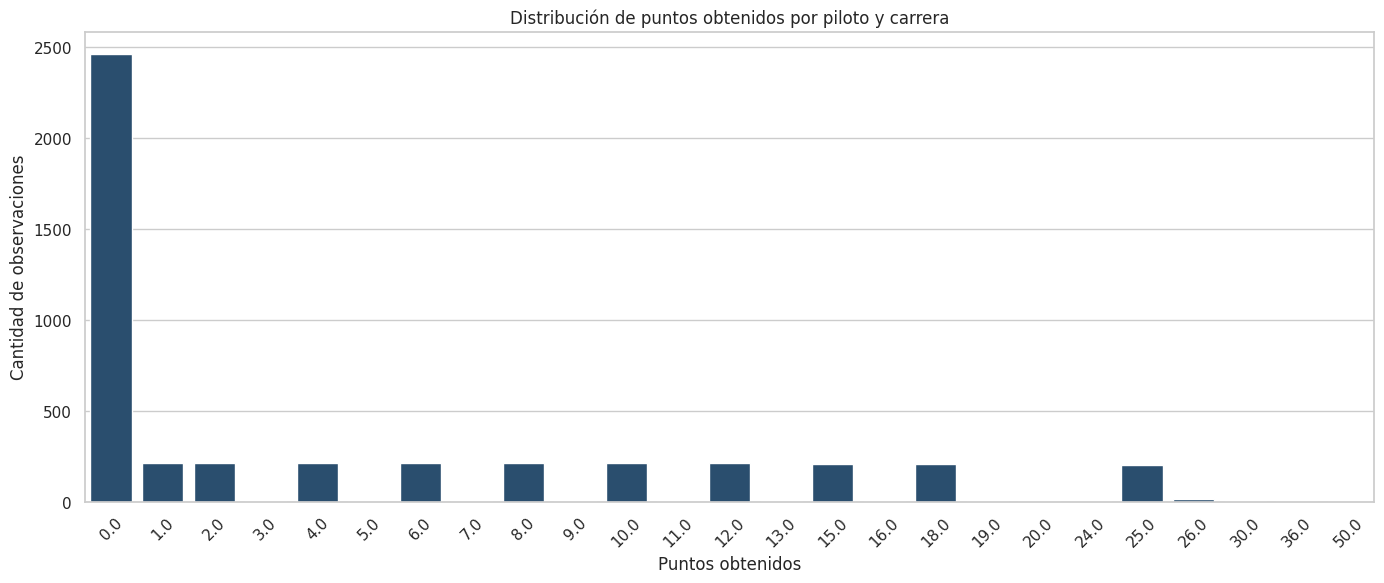

In [99]:
distribucion_puntos = (
    df_modelo_historico["Points"]
    .value_counts()
    .sort_index()
    .reset_index()
)

distribucion_puntos.columns = [
    "Points",
    "Observations"
]

plt.figure(figsize=(14, 6))

sns.barplot(
    data=distribucion_puntos,
    x="Points",
    y="Observations",
    color="#1F4E79"
)

plt.title("Distribución de puntos obtenidos por piloto y carrera")
plt.xlabel("Puntos obtenidos")
plt.ylabel("Cantidad de observaciones")
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()


,Grid_Position_Model,observaciones,puntos_promedio,probabilidad_de_puntuar
0,1,215,18.683721,91.162791
1,2,215,15.479070,88.372093
2,3,215,12.479070,85.581395
3,4,215,11.093023,86.976744
4,5,215,8.581395,77.674419
5,6,214,7.476636,74.766355
6,7,215,5.130233,68.372093
7,8,215,3.860465,59.534884
8,9,215,3.567442,57.674419
9,10,214,3.331776,55.607477


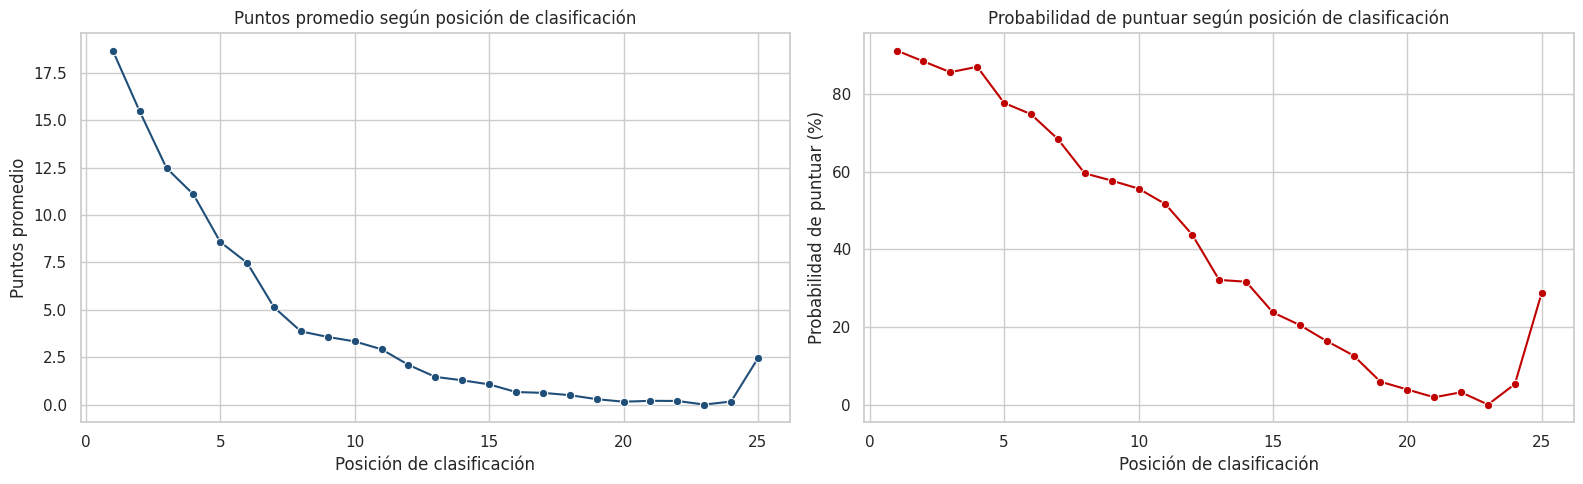

In [100]:
perfil_clasificacion = (
    df_modelo_historico
    .groupby("Grid_Position_Model", as_index=False)
    .agg(
        observaciones=("Points", "size"),
        puntos_promedio=("Points", "mean"),
        probabilidad_de_puntuar=("Scored_Points", "mean")
    )
)

perfil_clasificacion["probabilidad_de_puntuar"] = (
    perfil_clasificacion["probabilidad_de_puntuar"] * 100
)

display(perfil_clasificacion)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

sns.lineplot(
    data=perfil_clasificacion,
    x="Grid_Position_Model",
    y="puntos_promedio",
    marker="o",
    color="#1F4E79",
    ax=axes[0]
)

axes[0].set_title("Puntos promedio según posición de clasificación")
axes[0].set_xlabel("Posición de clasificación")
axes[0].set_ylabel("Puntos promedio")

sns.lineplot(
    data=perfil_clasificacion,
    x="Grid_Position_Model",
    y="probabilidad_de_puntuar",
    marker="o",
    color="#C00000",
    ax=axes[1]
)

axes[1].set_title("Probabilidad de puntuar según posición de clasificación")
axes[1].set_xlabel("Posición de clasificación")
axes[1].set_ylabel("Probabilidad de puntuar (%)")

plt.tight_layout()
plt.show()


,Variable,Correlacion_Spearman_con_Points
0,Grid_Position_Model,-0.672926
1,Driver_Previous_Grid_Position,-0.522449
2,Grid_Position_Special_Status,-0.044610
3,API_Round,0.002414
4,Driver_Previous_Points,0.486544
5,Constructor_Points_Before,0.556636
6,Driver_Points_Before,0.560820
7,Driver_Avg_Points_Before,0.607442
8,Constructor_Avg_Points_Before,0.615837


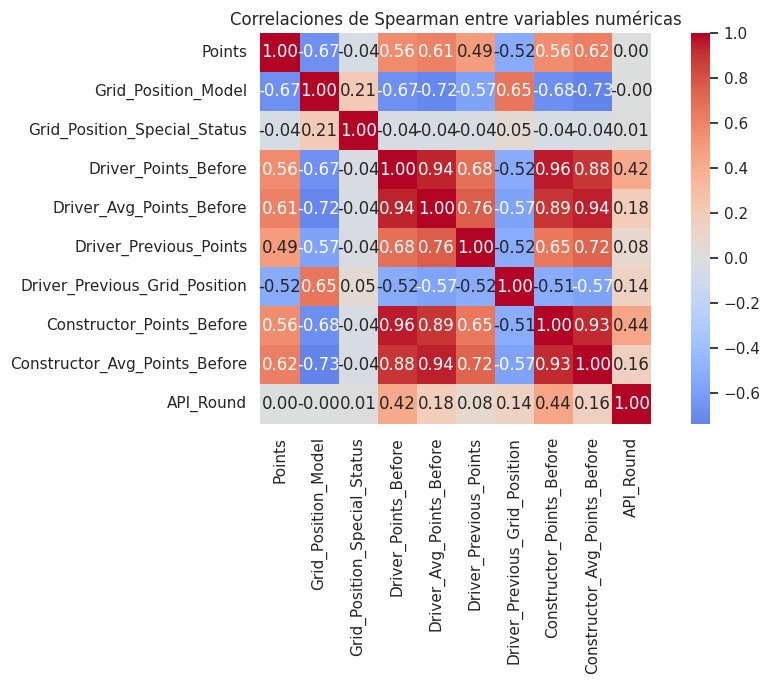

In [101]:
columnas_numericas_eda = [
    "Points",
    "Grid_Position_Model",
    "Grid_Position_Special_Status",
    "Driver_Points_Before",
    "Driver_Avg_Points_Before",
    "Driver_Previous_Points",
    "Driver_Previous_Grid_Position",
    "Constructor_Points_Before",
    "Constructor_Avg_Points_Before",
    "API_Round"
]

matriz_correlacion = (
    df_modelo_historico[columnas_numericas_eda]
    .corr(method="spearman")
)

correlaciones_con_puntos = (
    matriz_correlacion["Points"]
    .drop("Points")
    .sort_values()
    .reset_index()
)

correlaciones_con_puntos.columns = [
    "Variable",
    "Correlacion_Spearman_con_Points"
]

display(correlaciones_con_puntos)

plt.figure(figsize=(10, 7))

sns.heatmap(
    matriz_correlacion,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    square=True
)

plt.title("Correlaciones de Spearman entre variables numéricas")
plt.tight_layout()
plt.show()


,Year,puntos_promedio,porcentaje_pilotos_con_puntos
0,2010,4.200000,41.538462
1,2011,4.265033,42.093541
2,2012,4.234801,41.928721
3,2013,4.601918,45.563549
4,2014,4.975369,46.798030
5,2015,5.144772,50.938338
6,2016,4.620915,45.751634
7,2017,5.075377,50.251256
8,2018,5.093750,50.240385
9,2019,5.105012,49.880668


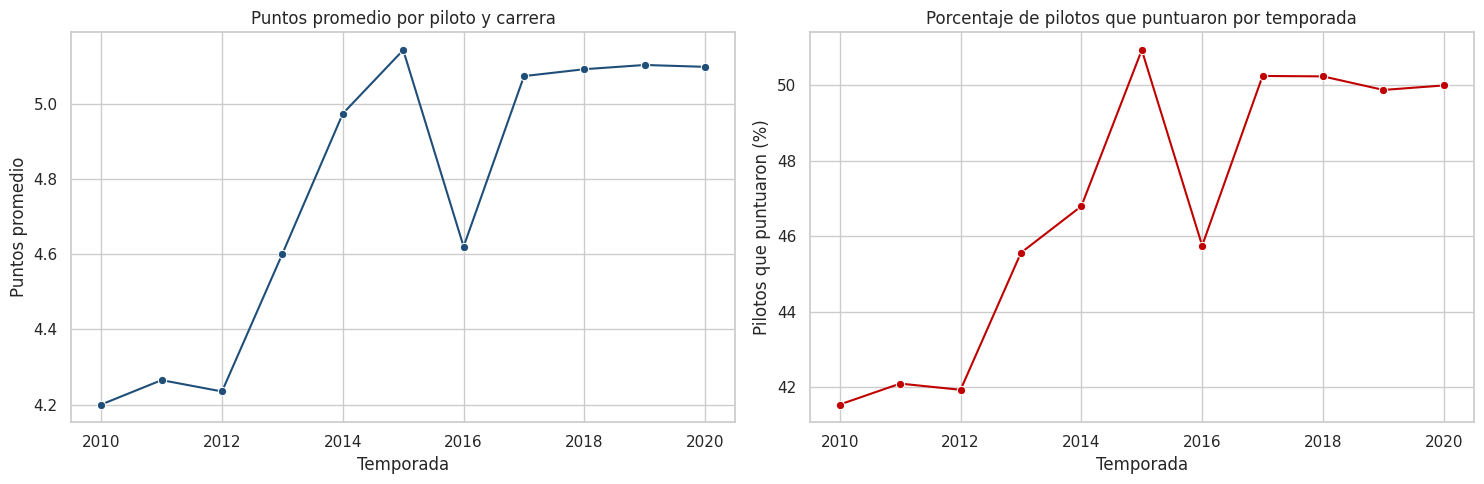

In [102]:
puntos_por_temporada = (
    df_modelo_historico
    .groupby("Year", as_index=False)
    .agg(
        puntos_promedio=("Points", "mean"),
        porcentaje_pilotos_con_puntos=("Scored_Points", "mean")
    )
)

puntos_por_temporada["porcentaje_pilotos_con_puntos"] = (
    puntos_por_temporada["porcentaje_pilotos_con_puntos"] * 100
)

display(puntos_por_temporada)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.lineplot(
    data=puntos_por_temporada,
    x="Year",
    y="puntos_promedio",
    marker="o",
    color="#1F4E79",
    ax=axes[0]
)

axes[0].set_title("Puntos promedio por piloto y carrera")
axes[0].set_xlabel("Temporada")
axes[0].set_ylabel("Puntos promedio")

sns.lineplot(
    data=puntos_por_temporada,
    x="Year",
    y="porcentaje_pilotos_con_puntos",
    marker="o",
    color="#C00000",
    ax=axes[1]
)

axes[1].set_title("Porcentaje de pilotos que puntuaron por temporada")
axes[1].set_xlabel("Temporada")
axes[1].set_ylabel("Pilotos que puntuaron (%)")

plt.tight_layout()
plt.show()


## Selección de variables y partición temporal

La variable objetivo es `Points`, correspondiente a los puntos obtenidos por un piloto en una carrera.

Se excluyen variables disponibles únicamente después de la carrera:

- `Race_Position`;
- `Laps`;
- `Time`;
- `Scored_Points`, ya que es una transformación directa de la variable objetivo.

La partición se realiza temporalmente para respetar el orden cronológico:

- entrenamiento: temporadas 2010–2018;
- validación: temporada 2019;
- prueba final: temporada 2020.

Esta estrategia simula un escenario realista, en el que se entrena con temporadas históricas y se predicen temporadas futuras.


In [103]:
# Variables numéricas disponibles antes de comenzar la carrera.
variables_numericas_modelo = [
    "Grid_Position_Model",
    "Grid_Position_Special_Status",
    "Driver_Avg_Points_Before",
    "Driver_Previous_Points",
    "Driver_Previous_Grid_Position",
    "Constructor_Avg_Points_Before",
    "API_Round"
]

# Variables categóricas disponibles antes de comenzar la carrera.
variables_categoricas_modelo = [
    "Driver_Code",
    "Constructor",
    "API_Circuit_ID"
]

variable_objetivo = "Points"

columnas_modelo = (
    variables_numericas_modelo
    + variables_categoricas_modelo
    + [
        "Year",
        variable_objetivo
    ]
)

df_modelado = (
    df_modelo_historico[columnas_modelo]
    .copy()
)

print("Filas disponibles para modelado:", len(df_modelado))

display(df_modelado.head())


Filas disponibles para modelado: 4609


,Grid_Position_Model,Grid_Position_Special_Status,Driver_Avg_Points_Before,Driver_Previous_Points,Driver_Previous_Grid_Position,Constructor_Avg_Points_Before,API_Round,Driver_Code,Constructor,API_Circuit_ID,Year,Points
0,18,0,0.0,0.0,0,0.0,1,ALG,STR Ferrari,bahrain,2010,0.0
1,3,0,0.0,0.0,0,0.0,1,ALO,Ferrari,bahrain,2010,25.0
2,11,0,0.0,0.0,0,0.0,1,BAR,Williams Cosworth,bahrain,2010,1.0
3,15,0,0.0,0.0,0,0.0,1,BUE,STR Ferrari,bahrain,2010,0.0
4,8,0,0.0,0.0,0,0.0,1,BUT,McLaren Mercedes,bahrain,2010,6.0


In [104]:
resumen_pre_modelado = pd.DataFrame({
    "Indicador": [
        "Filas totales",
        "Valores faltantes en predictores numéricos",
        "Valores faltantes en predictores categóricos",
        "Valores faltantes en objetivo",
        "Variables numéricas",
        "Variables categóricas"
    ],
    "Valor": [
        len(df_modelado),
        int(df_modelado[variables_numericas_modelo].isna().sum().sum()),
        int(df_modelado[variables_categoricas_modelo].isna().sum().sum()),
        int(df_modelado[variable_objetivo].isna().sum()),
        len(variables_numericas_modelo),
        len(variables_categoricas_modelo)
    ]
})

display(resumen_pre_modelado)

assert df_modelado[variables_numericas_modelo].isna().sum().sum() == 0
assert df_modelado[variables_categoricas_modelo].isna().sum().sum() == 0
assert df_modelado[variable_objetivo].isna().sum() == 0


,Indicador,Valor
0,Filas totales,4609
1,Valores faltantes en predictores numéricos,0
2,Valores faltantes en predictores categóricos,0
3,Valores faltantes en objetivo,0
4,Variables numéricas,7
5,Variables categóricas,3


In [105]:
df_train = (
    df_modelado[
        df_modelado["Year"] <= 2018
    ]
    .copy()
)

df_validacion = (
    df_modelado[
        df_modelado["Year"] == 2019
    ]
    .copy()
)

df_test = (
    df_modelado[
        df_modelado["Year"] == 2020
    ]
    .copy()
)

X_train = df_train[
    variables_numericas_modelo
    + variables_categoricas_modelo
]

y_train = df_train[variable_objetivo]

X_validacion = df_validacion[
    variables_numericas_modelo
    + variables_categoricas_modelo
]

y_validacion = df_validacion[variable_objetivo]

X_test = df_test[
    variables_numericas_modelo
    + variables_categoricas_modelo
]

y_test = df_test[variable_objetivo]

resumen_particiones = pd.DataFrame({
    "Conjunto": [
        "Entrenamiento",
        "Validación",
        "Prueba final"
    ],
    "Temporadas": [
        "2010–2018",
        "2019",
        "2020"
    ],
    "Filas": [
        len(df_train),
        len(df_validacion),
        len(df_test)
    ],
    "Puntos_promedio": [
        round(y_train.mean(), 2),
        round(y_validacion.mean(), 2),
        round(y_test.mean(), 2)
    ],
    "Porcentaje_con_puntos": [
        round((y_train > 0).mean() * 100, 2),
        round((y_validacion > 0).mean() * 100, 2),
        round((y_test > 0).mean() * 100, 2)
    ]
})

display(resumen_particiones)


,Conjunto,Temporadas,Filas,Puntos_promedio,Porcentaje_con_puntos
0,Entrenamiento,2010–2018,3850,4.67,45.90
1,Validación,2019,419,5.11,49.88
2,Prueba final,2020,340,5.10,50.00


## Entrenamiento y evaluación de modelos

Se comparan tres enfoques para predecir los puntos obtenidos por un piloto en una carrera:

1. un modelo baseline basado en el promedio histórico;
2. una regresión Ridge, que representa una aproximación lineal regularizada;
3. un modelo Random Forest, capaz de identificar relaciones no lineales.

La selección se realiza utilizando la temporada 2019 como conjunto de validación. Se emplean las métricas MAE, RMSE y coeficiente de determinación R².

Las predicciones negativas se reemplazan por cero, ya que los puntos obtenidos en Fórmula 1 no pueden ser negativos.


In [106]:
import numpy as np

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Preprocesamiento:
# - Variables numéricas: estandarización para Ridge.
# - Variables categóricas: codificación one-hot.
preprocesador = ColumnTransformer(
    transformers=[
        (
            "numericas",
            StandardScaler(),
            variables_numericas_modelo
        ),
        (
            "categoricas",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            variables_categoricas_modelo
        )
    ],
    remainder="drop"
)

def calcular_metricas(y_real, y_predicho, nombre_modelo):
    """
    Calcula métricas de regresión.
    Las predicciones se restringen a valores no negativos.
    """
    y_predicho = np.clip(
        np.asarray(y_predicho),
        a_min=0,
        a_max=None
    )

    return {
        "Modelo": nombre_modelo,
        "MAE": mean_absolute_error(y_real, y_predicho),
        "RMSE": np.sqrt(
            mean_squared_error(y_real, y_predicho)
        ),
        "R2": r2_score(y_real, y_predicho)
    }

# Baseline: predice el promedio de puntos observado en entrenamiento.
prediccion_baseline = np.repeat(
    y_train.mean(),
    len(y_validacion)
)

resultado_baseline = calcular_metricas(
    y_validacion,
    prediccion_baseline,
    "Baseline: promedio de entrenamiento"
)

display(
    pd.DataFrame([resultado_baseline]).round(3)
)


,Modelo,MAE,RMSE,R2
0,Baseline: promedio de entrenamiento,5.8,7.27,-0.004


In [107]:
resultados_ridge = []
modelos_ridge = {}

valores_alpha = [
    0.1,
    1,
    10,
    50,
    100
]

for alpha in valores_alpha:

    modelo_ridge = Pipeline(
        steps=[
            ("preprocesamiento", preprocesador),
            (
                "modelo",
                Ridge(
                    alpha=alpha
                )
            )
        ]
    )

    modelo_ridge.fit(X_train, y_train)

    prediccion_ridge = modelo_ridge.predict(
        X_validacion
    )

    metricas_ridge = calcular_metricas(
        y_validacion,
        prediccion_ridge,
        f"Ridge alpha={alpha}"
    )

    resultados_ridge.append(metricas_ridge)
    modelos_ridge[alpha] = modelo_ridge

df_resultados_ridge = (
    pd.DataFrame(resultados_ridge)
    .sort_values("MAE")
    .reset_index(drop=True)
)

display(df_resultados_ridge.round(3))

mejor_alpha_ridge = df_resultados_ridge.loc[
    0,
    "Modelo"
].replace("Ridge alpha=", "")

mejor_alpha_ridge = float(mejor_alpha_ridge)

mejor_modelo_ridge = modelos_ridge[
    mejor_alpha_ridge
]

print(
    "Mejor alpha para Ridge:",
    mejor_alpha_ridge
)


,Modelo,MAE,RMSE,R2
0,Ridge alpha=50,2.957,4.459,0.622
1,Ridge alpha=10,2.959,4.498,0.616
2,Ridge alpha=100,2.991,4.470,0.621
3,Ridge alpha=1,3.045,4.637,0.592
4,Ridge alpha=0.1,3.061,4.668,0.586


Mejor alpha para Ridge: 50.0


In [108]:
modelo_random_forest = Pipeline(
    steps=[
        ("preprocesamiento", preprocesador),
        (
            "modelo",
            RandomForestRegressor(
                n_estimators=400,
                max_depth=14,
                min_samples_leaf=2,
                max_features=0.8,
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

modelo_random_forest.fit(
    X_train,
    y_train
)

prediccion_random_forest = modelo_random_forest.predict(
    X_validacion
)

resultado_random_forest = calcular_metricas(
    y_validacion,
    prediccion_random_forest,
    "Random Forest"
)

resultados_validacion = (
    pd.DataFrame(
        [
            resultado_baseline,
            *resultados_ridge,
            resultado_random_forest
        ]
    )
    .sort_values("MAE")
    .reset_index(drop=True)
)

display(resultados_validacion.round(3))


,Modelo,MAE,RMSE,R2
0,Random Forest,2.838,4.401,0.632
1,Ridge alpha=50,2.957,4.459,0.622
2,Ridge alpha=10,2.959,4.498,0.616
3,Ridge alpha=100,2.991,4.470,0.621
4,Ridge alpha=1,3.045,4.637,0.592
5,Ridge alpha=0.1,3.061,4.668,0.586
6,Baseline: promedio de entrenamiento,5.800,7.270,-0.004


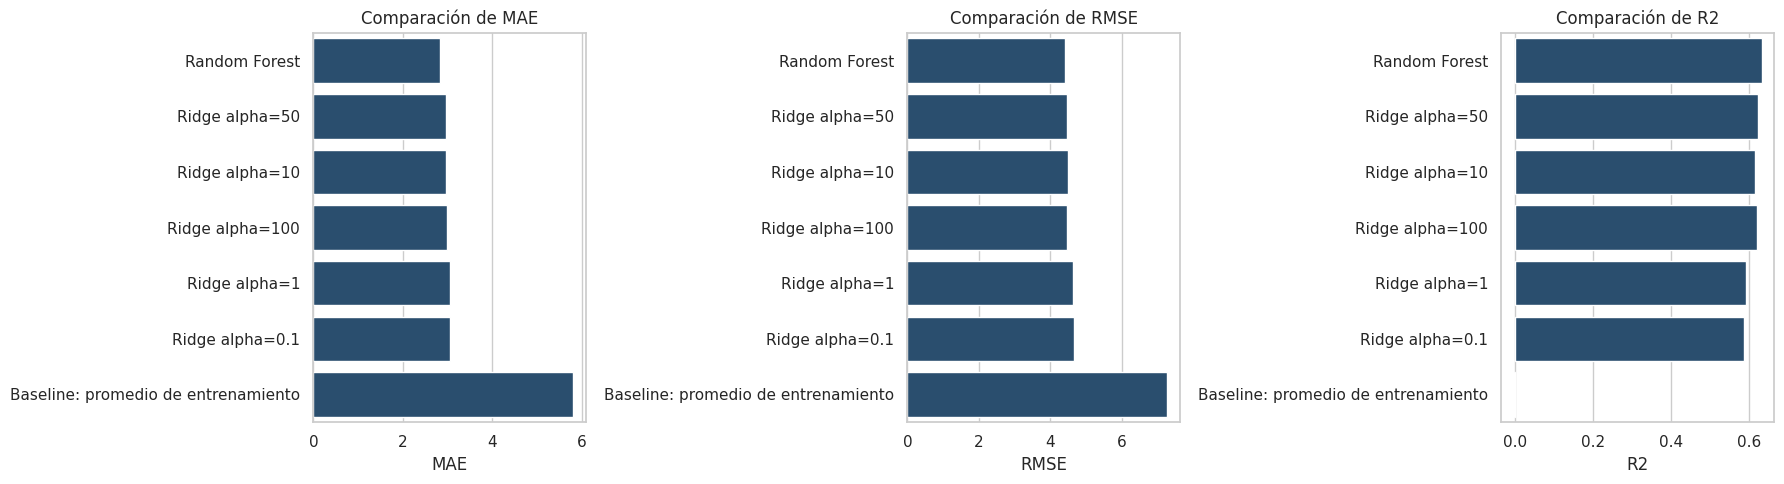

In [109]:
resultados_grafico = (
    resultados_validacion
    .melt(
        id_vars="Modelo",
        value_vars=["MAE", "RMSE", "R2"],
        var_name="Métrica",
        value_name="Valor"
    )
)

fig, axes = plt.subplots(
    1,
    3,
    figsize=(18, 5)
)

metricas_grafico = ["MAE", "RMSE", "R2"]

for ax, metrica in zip(axes, metricas_grafico):

    datos_metrica = resultados_grafico[
        resultados_grafico["Métrica"] == metrica
    ]

    sns.barplot(
        data=datos_metrica,
        x="Valor",
        y="Modelo",
        color="#1F4E79",
        ax=ax
    )

    ax.set_title(f"Comparación de {metrica}")
    ax.set_xlabel(metrica)
    ax.set_ylabel("")

plt.tight_layout()
plt.show()


## Evaluación final sobre la temporada 2020

El modelo Random Forest fue seleccionado a partir de su desempeño sobre la temporada de validación 2019.

Para la evaluación final, los modelos se reentrenan utilizando las temporadas 2010–2019. Luego, se evalúan sobre la temporada 2020, que permaneció separada durante la selección de modelo.

La temporada 2020 se utiliza exclusivamente como conjunto de prueba final y no interviene en ninguna decisión de ajuste o selección.


In [110]:
from sklearn.base import clone

# Datos históricos disponibles hasta el cierre de 2019.
df_entrenamiento_final = (
    df_modelado[
        df_modelado["Year"] <= 2019
    ]
    .copy()
)

X_entrenamiento_final = df_entrenamiento_final[
    variables_numericas_modelo
    + variables_categoricas_modelo
]

y_entrenamiento_final = df_entrenamiento_final[
    variable_objetivo
]

# Se clonan los pipelines para conservar el flujo de entrenamiento limpio.
modelo_ridge_final = clone(mejor_modelo_ridge)

modelo_random_forest_final = clone(
    modelo_random_forest
)

# Entrenamiento final, sin utilizar registros de 2020.
modelo_ridge_final.fit(
    X_entrenamiento_final,
    y_entrenamiento_final
)

modelo_random_forest_final.fit(
    X_entrenamiento_final,
    y_entrenamiento_final
)

# Predicciones para la temporada de prueba final.
prediccion_baseline_test = np.repeat(
    y_entrenamiento_final.mean(),
    len(y_test)
)

prediccion_ridge_test = np.clip(
    modelo_ridge_final.predict(X_test),
    a_min=0,
    a_max=None
)

prediccion_random_forest_test = np.clip(
    modelo_random_forest_final.predict(X_test),
    a_min=0,
    a_max=None
)

resultados_test_final = (
    pd.DataFrame([
        calcular_metricas(
            y_test,
            prediccion_baseline_test,
            "Baseline: promedio de entrenamiento"
        ),
        calcular_metricas(
            y_test,
            prediccion_ridge_test,
            "Ridge alpha=50"
        ),
        calcular_metricas(
            y_test,
            prediccion_random_forest_test,
            "Random Forest seleccionado"
        )
    ])
    .sort_values("MAE")
    .reset_index(drop=True)
)

display(resultados_test_final.round(3))


,Modelo,MAE,RMSE,R2
0,Random Forest seleccionado,3.570,5.227,0.480
1,Ridge alpha=50,3.699,5.233,0.479
2,Baseline: promedio de entrenamiento,5.797,7.257,-0.003


In [111]:
df_resultados_2020 = (
    df_modelo_historico
    .loc[
        df_test.index,
        [
            "Year",
            "API_Round",
            "API_Race_Name",
            "Driver",
            "Constructor",
            "Grid_Position_Model",
            "Points"
        ]
    ]
    .copy()
)

df_resultados_2020["Predicted_Points_Random_Forest"] = (
    prediccion_random_forest_test
)

df_resultados_2020["Absolute_Error"] = (
    df_resultados_2020["Points"]
    - df_resultados_2020["Predicted_Points_Random_Forest"]
).abs()

df_resultados_2020 = (
    df_resultados_2020
    .sort_values(
        ["API_Round", "Predicted_Points_Random_Forest"],
        ascending=[True, False]
    )
)

display(df_resultados_2020.head(20))


,Year,API_Round,API_Race_Name,Driver,Constructor,Grid_Position_Model,Points,Predicted_Points_Random_Forest,Absolute_Error
4270,2020,1,Austrian Grand Prix,Valtteri Bottas,Mercedes,1,25.0,17.596863,7.403137
4274,2020,1,Austrian Grand Prix,Lewis Hamilton,Mercedes,2,12.0,17.111939,5.111939
4287,2020,1,Austrian Grand Prix,Max Verstappen,Red Bull Racing Honda,3,0.0,12.612008,12.612008
4279,2020,1,Austrian Grand Prix,Lando Norris,McLaren Renault,4,16.0,11.015488,4.984512
4269,2020,1,Austrian Grand Prix,Alexander Albon,Red Bull Racing Honda,5,0.0,8.117458,8.117458
4281,2020,1,Austrian Grand Prix,Sergio Perez,Racing Point BWT Mercedes,6,8.0,6.328530,1.671470
4277,2020,1,Austrian Grand Prix,Charles Leclerc,Ferrari,7,18.0,5.108860,12.891140
4288,2020,1,Austrian Grand Prix,Sebastian Vettel,Ferrari,11,1.0,3.568697,2.568697
4285,2020,1,Austrian Grand Prix,Carlos Sainz,McLaren Renault,8,10.0,3.445652,6.554348
4286,2020,1,Austrian Grand Prix,Lance Stroll,Racing Point BWT Mercedes,9,0.0,1.908648,1.908648


In [112]:
nombres_variables_transformadas = (
    modelo_random_forest_final
    .named_steps["preprocesamiento"]
    .get_feature_names_out()
)

importancias_random_forest = (
    pd.DataFrame({
        "Variable": nombres_variables_transformadas,
        "Importancia": (
            modelo_random_forest_final
            .named_steps["modelo"]
            .feature_importances_
        )
    })
    .sort_values("Importancia", ascending=False)
    .reset_index(drop=True)
)

# Se eliminan prefijos técnicos para una lectura más clara.
importancias_random_forest["Variable"] = (
    importancias_random_forest["Variable"]
    .str.replace("numericas__", "", regex=False)
    .str.replace("categoricas__", "", regex=False)
)

display(importancias_random_forest.head(20))


,Variable,Importancia
0,Grid_Position_Model,0.517781
1,Constructor_Avg_Points_Before,0.154629
2,Driver_Avg_Points_Before,0.123082
3,Driver_Previous_Grid_Position,0.035741
4,API_Round,0.035174
5,Driver_Previous_Points,0.024714
6,Constructor_McLaren Mercedes,0.004914
7,Driver_Code_HAM,0.004460
8,Driver_Code_VET,0.004323
9,Constructor_Ferrari,0.004264


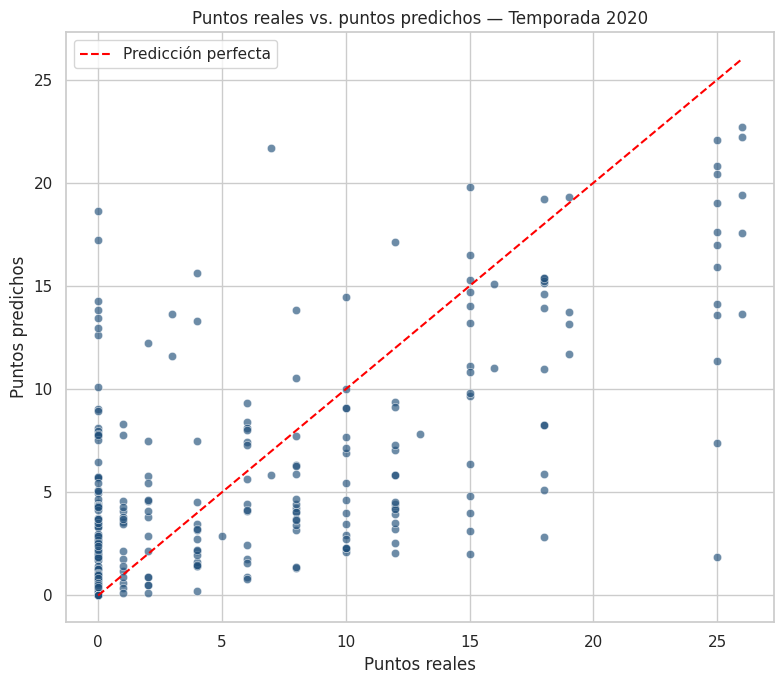

In [113]:
plt.figure(figsize=(8, 7))

sns.scatterplot(
    data=df_resultados_2020,
    x="Points",
    y="Predicted_Points_Random_Forest",
    alpha=0.65,
    color="#1F4E79"
)

limite_maximo = max(
    df_resultados_2020["Points"].max(),
    df_resultados_2020[
        "Predicted_Points_Random_Forest"
    ].max()
)

plt.plot(
    [0, limite_maximo],
    [0, limite_maximo],
    linestyle="--",
    color="red",
    label="Predicción perfecta"
)

plt.title("Puntos reales vs. puntos predichos — Temporada 2020")
plt.xlabel("Puntos reales")
plt.ylabel("Puntos predichos")
plt.legend()

plt.tight_layout()
plt.show()


In [114]:
df_resultados_2020["Grupo_de_puntos_reales"] = pd.cut(
    df_resultados_2020["Points"],
    bins=[-1, 0, 10, float("inf")],
    labels=[
        "Sin puntos",
        "Entre 1 y 10 puntos",
        "Más de 10 puntos"
    ]
)

resumen_error_por_grupo = (
    df_resultados_2020
    .groupby(
        "Grupo_de_puntos_reales",
        observed=False,
        as_index=False
    )
    .agg(
        observaciones=("Points", "size"),
        puntos_reales_promedio=("Points", "mean"),
        puntos_predichos_promedio=(
            "Predicted_Points_Random_Forest",
            "mean"
        ),
        mae_promedio=("Absolute_Error", "mean")
    )
)

resumen_error_por_grupo[
    [
        "puntos_reales_promedio",
        "puntos_predichos_promedio",
        "mae_promedio"
    ]
] = resumen_error_por_grupo[
    [
        "puntos_reales_promedio",
        "puntos_predichos_promedio",
        "mae_promedio"
    ]
].round(2)

display(resumen_error_por_grupo)


,Grupo_de_puntos_reales,observaciones,puntos_reales_promedio,puntos_predichos_promedio,mae_promedio
0,Sin puntos,170,0.00,2.36,2.36
1,Entre 1 y 10 puntos,102,5.22,4.80,3.45
2,Más de 10 puntos,68,17.68,11.30,6.77


## Conclusiones y limitaciones

Se desarrolló un modelo de regresión para predecir los puntos obtenidos por cada piloto en una carrera de Fórmula 1.

El conjunto de datos principal fue obtenido desde Kaggle y enriquecido mediante la API pública Jolpica. La información adicional incorporada incluyó datos de calendario, circuito, país, fecha y número de ronda. Posteriormente, se construyeron variables históricas de piloto y constructor utilizando exclusivamente resultados de carreras anteriores, con el objetivo de evitar fuga de información.

La variable objetivo fue `Points`. Debido a que el 53.44% de las observaciones no obtuvo puntos, se identificó una distribución concentrada en cero. La posición de clasificación fue la variable con mayor relación con el resultado final y también la más relevante según el modelo Random Forest.

La evaluación se realizó mediante una partición temporal: las temporadas 2010–2018 se utilizaron para entrenamiento, 2019 para validación y 2020 como conjunto de prueba final. Esta estrategia permitió simular un escenario realista, en el cual se predicen resultados de una temporada futura utilizando únicamente información histórica.

Durante la validación de 2019, el modelo Random Forest obtuvo el mejor desempeño, con un MAE de 2.838, un RMSE de 4.401 y un R² de 0.632. Por este motivo fue seleccionado como modelo final.

En la evaluación final sobre la temporada 2020, el Random Forest alcanzó un MAE de 3.570, un RMSE de 5.227 y un R² de 0.480. El modelo superó al baseline basado en el promedio histórico, reduciendo el error absoluto medio en aproximadamente 38.4%. También obtuvo un desempeño ligeramente superior a la regresión Ridge, que alcanzó un MAE de 3.699.

Las variables más importantes para el modelo fueron la posición de clasificación, el promedio histórico de puntos del constructor y el promedio histórico de puntos del piloto. Esto indica que el rendimiento previo de la escudería, el desempeño reciente del piloto y la posición de salida son factores relevantes para anticipar los puntos finales.

El análisis de errores mostró que el modelo tiende a sobreestimar a los pilotos que finalmente no obtienen puntos: para las 170 observaciones sin puntos, la predicción promedio fue de 2.36 puntos. También tiende a subestimar los resultados altos: en las 68 observaciones con más de 10 puntos, el promedio real fue de 17.68 puntos, mientras que el promedio predicho fue de 11.30 puntos. El mayor error promedio se observó en este grupo de puntajes altos, con un MAE de 6.77.

Las principales limitaciones del modelo son la ausencia de variables relacionadas con abandonos, accidentes, penalizaciones, clima, estrategia de carrera, seguridad, fallas mecánicas y eventos inesperados. Estos factores pueden modificar significativamente el resultado final y no están disponibles antes de la carrera dentro del conjunto de datos utilizado.

En conclusión, el modelo construido ofrece una capacidad predictiva útil basada en variables disponibles antes de la carrera. Sin embargo, los resultados deben interpretarse como una estimación probabilística del rendimiento esperado y no como una predicción exacta del resultado final.
